# ECE 662 Team 9: INT4 Collapse Diagnosis

**Owner**: Amanda Nemshin

Based on Lilly's `B_02_Shared_Model_Quantization` notebook (cells 1–28), made portable for Mac (MPS) and Colab.

**Step 1 — sanity check.** Expected on the full test set: FP32 ≈ 89.82%, W8 ≈ 89.87%, W4 ≈ 17.58% (unfolded and folded).

**Step 2: Checkpoint 1 analysis** (bottom of the notebook): hub-model comparison, per-layer weight stats, W4 output error, activation ranges, figures. Outputs go to `results/`.

**Step 3: Checkpoint 2** (after Checkpoint 1): block protection, block vs top-k at matched storage, W4-region test, compounding by block, MSE-clip and bias-correction tests.

**Steps 4–5: Checkpoints 3 and 4**: fixed-A8 reruns, Pareto frontier, retrained variants (run `retrain_variants.py` first), evidence table, slide figures, handoff files.


In [1]:
# ---- Environment setup: works on Mac (local) and Google Colab ----
import os, sys, subprocess
import torch

IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/josie-barber/Layer-Wise-Quantization-of-MobileNetV2-for-Edge-Accelerators.git"

if IN_COLAB:
    REPO_DIR = "/content/Layer-Wise-Quantization-of-MobileNetV2-for-Edge-Accelerators"
    if not os.path.exists(REPO_DIR):
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, REPO_DIR], check=True)
else:
    REPO_DIR = os.path.abspath(".")   # the folder this notebook is in

CKPT_PATH = os.path.join(REPO_DIR, "mobilenetv2_cifar10-2.pth")
DATA_DIR  = os.path.join(REPO_DIR, "data")
OUT_DIR   = os.path.join(REPO_DIR, "results")
os.makedirs(OUT_DIR, exist_ok=True)

# Best available device: NVIDIA GPU (Colab) > Apple GPU (Mac) > CPU
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

# Multi-worker loading hangs in Jupyter on macOS; it's fine on Colab
NUM_WORKERS = 2 if IN_COLAB else 0
PIN_MEMORY = device.type == "cuda"

print(f"Colab: {IN_COLAB} | device: {device} | repo: {REPO_DIR}")
assert os.path.exists(CKPT_PATH), f"Checkpoint not found at {CKPT_PATH}"


Colab: False | device: mps | repo: /Users/amandanemshin/Desktop/Duke/Senior/ECE662/Layer-Wise-Quantization-of-MobileNetV2-for-Edge-Accelerators


# **MobileNetV2 Quantization and Layer Sensitivity**

# ECE 662 — Team 9

**Owner**: Lilly Press

**Goal**: Compare 8-bit and 4-bit weight quantization, then identify which layers lose the most accuracy when reduced to 4 bits.  

**Current stage**: Uniform weight quantization. Activations remain FP32 during initial debugging; final experiments will use fixed 8-bit activations.

# 1. Setup and Imports

In [2]:
import copy
import random

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torchvision
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset

# Set seeds for reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# Use a GPU if available; otherwise use the CPU
# device is set in the environment setup cell above

print(f"PyTorch version: {torch.__version__}")
print(f"Torchvision version: {torchvision.__version__}")
print(f"Device: {device}")

if device.type == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")

PyTorch version: 2.15.0
Torchvision version: 0.29.2
Device: mps


# 2. Load the Baseline Model

In [3]:
# Load the team's shared trained model
from torchvision.models import mobilenet_v2

baseline_model = mobilenet_v2(weights=None)
baseline_model.classifier[1] = nn.Linear(
    baseline_model.last_channel, 10
)

state_dict = torch.load(
    CKPT_PATH,
    map_location="cpu",
    weights_only=True
)

baseline_model.load_state_dict(state_dict, strict=True)
baseline_model = baseline_model.to(device).eval()

print("Shared checkpoint loaded successfully!")
print("Device:", device)

Shared checkpoint loaded successfully!
Device: mps


# 3. Load CIFAR-10

In [4]:
# Convert images to tensors and normalize each color channel
# Match Josie's evaluation preprocessing
transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=(0.485, 0.456, 0.406),
        std=(0.229, 0.224, 0.225)
    )
])

# Download the CIFAR-10 test set
test_dataset = datasets.CIFAR10(
    root=DATA_DIR,
    train=False,
    download=True,
    transform=transform
)

# Full test set for reporting final accuracy
test_loader = DataLoader(
    test_dataset,
    batch_size=128,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY
)

# Small test subset for quick debugging only
generator = torch.Generator().manual_seed(SEED)
debug_indices = torch.randperm(
    len(test_dataset), generator=generator
)[:1000].tolist()

debug_loader = DataLoader(
    Subset(test_dataset, debug_indices),
    batch_size=128,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY
)

print(f"Full test set: {len(test_dataset):,} images")
print(f"Debug subset: {len(debug_indices):,} images")
print(f"Classes: {test_dataset.classes}")

Full test set: 10,000 images
Debug subset: 1,000 images
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


# 4. Check FP32 Accuracy

In [5]:
# Reuse this function for every model configuration
def evaluate(model, loader):
    model.eval()
    model_device = next(model.parameters()).device

    correct = 0
    total = 0

    with torch.inference_mode():
        for images, labels in loader:
            images = images.to(model_device)
            labels = labels.to(model_device)

            outputs = model(images)
            predictions = outputs.argmax(dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    if total == 0:
        raise ValueError("The data loader contains no images.")

    return 100.0 * correct / total


# Start with the smaller subset to check everything works
fp32_debug_accuracy = evaluate(baseline_model, debug_loader)
print(f"FP32 debug accuracy: {fp32_debug_accuracy:.2f}%")

FP32 debug accuracy: 89.00%


In [6]:
fp32_test_accuracy = evaluate(baseline_model, test_loader)
print(f"FP32 full-test accuracy: {fp32_test_accuracy:.2f}%")

FP32 full-test accuracy: 89.82%


# 5. Define Weight Quantization

In [7]:
def quantize_weights(weights, bits):
    """Simulate symmetric quantization per output channel."""
    if bits not in (4, 8):
        raise ValueError("bits must be 4 or 8")

    # Symmetric integer range: -7 to 7 or -127 to 127
    qmax = (2 ** (bits - 1)) - 1

    # Dimension 0 represents output channels for Conv2d and Linear.
    # Find the maximum magnitude within each output channel.
    reduce_dims = tuple(range(1, weights.ndim))
    max_abs = weights.abs().amax(dim=reduce_dims, keepdim=True)

    # Use scale 1 for all-zero channels to avoid division by zero
    scale = torch.where(
        max_abs > 0,
        max_abs / qmax,
        torch.ones_like(max_abs)
    )

    integer_weights = torch.round(weights / scale)
    integer_weights = torch.clamp(integer_weights, -qmax, qmax)

    # Convert back to floating point for ordinary PyTorch inference
    return integer_weights * scale


def quantize_model_weights(model, bits):
    """Return a quantized copy, leaving the original model unchanged."""
    quantized_model = copy.deepcopy(model)
    quantized_model.eval()

    with torch.no_grad():
        for name, layer in quantized_model.named_modules():
            if isinstance(layer, (nn.Conv2d, nn.Linear)):
                layer.weight.copy_(
                    quantize_weights(layer.weight, bits)
                )

    return quantized_model


print("Weight quantization functions are ready.")

Weight quantization functions are ready.


# 6. Run Uniform 8-bit Weights

In [8]:
# Create an 8-bit weight version from the untouched baseline
model_w8 = quantize_model_weights(baseline_model, bits=8)

# Check accuracy on the same debugging subset as FP32
w8_debug_accuracy = evaluate(model_w8, debug_loader)

print("Configuration: W8 / FP32 activations")
print(f"FP32 debug accuracy: {fp32_debug_accuracy:.2f}%")
print(f"W8 debug accuracy:   {w8_debug_accuracy:.2f}%")
print(
    f"Accuracy drop: "
    f"{fp32_debug_accuracy - w8_debug_accuracy:.2f} percentage points"
)

Configuration: W8 / FP32 activations
FP32 debug accuracy: 89.00%
W8 debug accuracy:   89.70%
Accuracy drop: -0.70 percentage points


In [9]:
w8_test_accuracy = evaluate(model_w8, test_loader)

print(f"W8 full-test accuracy: {w8_test_accuracy:.2f}%")
print(
    f"Accuracy drop from FP32: "
    f"{fp32_test_accuracy - w8_test_accuracy:.2f} percentage points"
)

W8 full-test accuracy: 89.87%
Accuracy drop from FP32: -0.05 percentage points


# 7. Run Uniform 4-bit Weights

In [10]:
# Create a fresh 4-bit version from the original FP32 model
model_w4 = quantize_model_weights(baseline_model, bits=4)

w4_debug_accuracy = evaluate(model_w4, debug_loader)

print("Configuration: W4 / FP32 activations")
print(f"FP32 debug accuracy: {fp32_debug_accuracy:.2f}%")
print(f"W4 debug accuracy:   {w4_debug_accuracy:.2f}%")
print(
    f"Accuracy drop: "
    f"{fp32_debug_accuracy - w4_debug_accuracy:.2f} percentage points"
)

Configuration: W4 / FP32 activations
FP32 debug accuracy: 89.00%
W4 debug accuracy:   19.10%
Accuracy drop: 69.90 percentage points


In [11]:
w4_test_accuracy = evaluate(model_w4, test_loader)

print(f"W4 full-test accuracy: {w4_test_accuracy:.2f}%")
print(
    f"Accuracy drop from FP32: "
    f"{fp32_test_accuracy - w4_test_accuracy:.2f} percentage points"
)

W4 full-test accuracy: 17.58%
Accuracy drop from FP32: 72.24 percentage points


# 8. Calculate Estimated Weight Storage

In [12]:
def estimate_weight_storage(model, bits):
    """Packed Conv2d/Linear weight payload only, in decimal MB."""
    weight_count = sum(
        layer.weight.numel()
        for layer in model.modules()
        if isinstance(layer, (nn.Conv2d, nn.Linear))
    )

    return weight_count * bits / 8 / 1_000_000


storage_results = pd.DataFrame({
    "Weight precision": ["FP32", "8-bit", "4-bit"],
    "Estimated weight payload (MB)": [
        estimate_weight_storage(baseline_model, 32),
        estimate_weight_storage(baseline_model, 8),
        estimate_weight_storage(baseline_model, 4)
    ]
})

print(storage_results.to_string(index=False))

Weight precision  Estimated weight payload (MB)
            FP32                        8.81024
           8-bit                        2.20256
           4-bit                        1.10128


# 9. Compare Baseline Results

In [13]:
baseline_results = pd.DataFrame({
    "Configuration": [
        "FP32",
        "W8 / FP32 activations",
        "W4 / FP32 activations"
    ],
    "Test accuracy (%)": [
        fp32_test_accuracy,
        w8_test_accuracy,
        w4_test_accuracy
    ],
    "Drop from FP32 (percentage points)": [
        0.0,
        fp32_test_accuracy - w8_test_accuracy,
        fp32_test_accuracy - w4_test_accuracy
    ],
    "Estimated weight payload (MB)": [
        estimate_weight_storage(baseline_model, 32),
        estimate_weight_storage(baseline_model, 8),
        estimate_weight_storage(baseline_model, 4)
    ]
})

display(baseline_results.round(3))

,Configuration,Test accuracy (%),Drop from FP32 (percentage points),Estimated weight payload (MB)
0,FP32,89.82,0.00,8.810
1,W8 / FP32 activations,89.87,-0.05,2.203
2,W4 / FP32 activations,17.58,72.24,1.101


# 10. Add per-layer precision

In [14]:
# Names of all layers eligible for weight quantization
eligible_layers = [
    name
    for name, layer in baseline_model.named_modules()
    if isinstance(layer, (nn.Conv2d, nn.Linear))
]


def quantize_model_by_layer(model, bit_config):
    """Quantize a fresh model copy using a layer-name-to-bits dictionary."""
    model_layers = {
        name: layer
        for name, layer in model.named_modules()
        if isinstance(layer, (nn.Conv2d, nn.Linear))
    }

    # Require a precision assignment for every eligible layer
    if set(bit_config) != set(model_layers):
        raise ValueError(
            "bit_config must contain exactly the eligible layer names."
        )

    if any(bits not in (4, 8) for bits in bit_config.values()):
        raise ValueError("Each layer must use 4 or 8 bits.")

    quantized_model = copy.deepcopy(model)
    quantized_model.eval()

    with torch.no_grad():
        for name, layer in quantized_model.named_modules():
            if name in bit_config:
                layer.weight.copy_(
                    quantize_weights(layer.weight, bit_config[name])
                )

    return quantized_model


# Start with every eligible layer at 8 bits
all_w8_config = {name: 8 for name in eligible_layers}

# Example: change only the first eligible layer to 4 bits
example_config = all_w8_config.copy()
example_config[eligible_layers[0]] = 4

print(f"Eligible layers: {len(eligible_layers)}")
print(f"Example 4-bit layer: {eligible_layers[0]}")
print("Per-layer quantization function is ready.")

Eligible layers: 53
Example 4-bit layer: features.0.0
Per-layer quantization function is ready.


In [15]:
# Build an all-8-bit model using the per-layer configuration
model_w8_by_layer = quantize_model_by_layer(
    baseline_model, all_w8_config
)

# Its weights and other state should match the existing W8 model
for name, value in model_w8.state_dict().items():
    assert torch.equal(
        value, model_w8_by_layer.state_dict()[name]
    ), f"Mismatch in: {name}"

print("Passed: per-layer all-W8 matches the uniform W8 model.")

# Check that the example mixed configuration runs
example_mixed_model = quantize_model_by_layer(
    baseline_model, example_config
)

example_debug_accuracy = evaluate(
    example_mixed_model, debug_loader
)

print(f"4-bit layer: {eligible_layers[0]}")
print(f"All other eligible layers: 8 bits")
print(f"Debug accuracy: {example_debug_accuracy:.2f}%")

Passed: per-layer all-W8 matches the uniform W8 model.
4-bit layer: features.0.0
All other eligible layers: 8 bits
Debug accuracy: 87.90%


# 11. Fold Batch Normalization

In [16]:
from torch.nn.utils import fuse_conv_bn_eval

def fold_batch_norm(model):
    folded_model = copy.deepcopy(model).eval()
    folded_pairs = []

    def fold_sequential_pairs(module, prefix=""):
        # Recurse into nested modules
        for name, child in list(module.named_children()):
            child_prefix = f"{prefix}.{name}" if prefix else name
            fold_sequential_pairs(child, child_prefix)

        # Only combine adjacent layers in Sequential containers
        if isinstance(module, nn.Sequential):
            children = list(module.named_children())

            for i in range(len(children) - 1):
                conv_name, conv = children[i]
                bn_name, bn = children[i + 1]

                if isinstance(conv, nn.Conv2d) and isinstance(
                    bn, nn.BatchNorm2d
                ):
                    module._modules[conv_name] = fuse_conv_bn_eval(
                        conv, bn
                    )
                    module._modules[bn_name] = nn.Identity()
                    folded_pairs.append(
                        f"{prefix}.{conv_name}" if prefix else conv_name
                    )

    fold_sequential_pairs(folded_model)

    remaining_bn = sum(
        isinstance(layer, nn.BatchNorm2d)
        for layer in folded_model.modules()
    )
    if remaining_bn:
        raise ValueError(
            f"{remaining_bn} batch-normalization layers remain; "
            "check the model structure."
        )

    return folded_model, folded_pairs


# Preserve the original baseline
folded_baseline, folded_pairs = fold_batch_norm(baseline_model)

# Compare outputs on one real image batch
images, _ = next(iter(debug_loader))
images = images.to(next(baseline_model.parameters()).device)

with torch.inference_mode():
    original_outputs = baseline_model(images)
    folded_outputs = folded_baseline(images)

max_difference = (
    original_outputs - folded_outputs
).abs().max().item()

torch.testing.assert_close(
    folded_outputs,
    original_outputs,
    rtol=1e-3,
    atol=1e-4
)

print(f"Folded convolution/BN pairs: {len(folded_pairs)}")
print(f"Maximum output difference: {max_difference:.8f}")
print("Passed: folding preserves FP32 outputs within tolerance.")

Folded convolution/BN pairs: 52
Maximum output difference: 0.00006437
Passed: folding preserves FP32 outputs within tolerance.


# 12. Evaluate Folded Weight-Only Baselines

In [17]:
# Keep earlier models and results unchanged.
# Quantize fresh copies AFTER BatchNorm folding.
folded_w8_model = quantize_model_weights(folded_baseline, bits=8)
folded_w4_model = quantize_model_weights(folded_baseline, bits=4)

folded_fp32_accuracy = evaluate(folded_baseline, test_loader)
folded_w8_accuracy = evaluate(folded_w8_model, test_loader)
folded_w4_accuracy = evaluate(folded_w4_model, test_loader)

folded_results = pd.DataFrame({
    "Configuration": [
        "Folded FP32",
        "Folded W8 / FP32 activations",
        "Folded W4 / FP32 activations"
    ],
    "Test accuracy (%)": [
        folded_fp32_accuracy,
        folded_w8_accuracy,
        folded_w4_accuracy
    ],
    "Drop from folded FP32 (percentage points)": [
        0.0,
        folded_fp32_accuracy - folded_w8_accuracy,
        folded_fp32_accuracy - folded_w4_accuracy
    ]
})

display(folded_results.round(3))

,Configuration,Test accuracy (%),Drop from folded FP32 (percentage points)
0,Folded FP32,89.82,0.00
1,Folded W8 / FP32 activations,89.87,-0.05
2,Folded W4 / FP32 activations,17.58,72.24


# Checkpoint 1 (Nov 4–10): Why does uniform W4 collapse?

This section compares the team's shared checkpoint against the torch.hub CIFAR-10 MobileNetV2
using the **same per-channel symmetric weight quantizer** and each model's **own preprocessing**:

| | Shared model (ours) | Hub model (chenyaofo) |
|---|---|---|
| Training | ImageNet-pretrained, fine-tuned 10 epochs on CIFAR-10 | Trained on CIFAR-10 |
| Input | 64×64, ImageNet mean/std | 32×32, CIFAR mean/std |

Outputs (saved to `results/`):
- `checkpoint_comparison.csv`: FP32 / W8 / W4 accuracy for both models
- `layer_weight_stats.csv`: per-layer weight distributions, outliers, weight quantization error
- `layer_quantization_error.csv`: per-layer output error at W4 (isolated vs cumulative) and activation ranges
- Figures: `fig_*.png`

Activations stay FP32 here (weight-only), matching the midterm. Checkpoint 3 reruns key results at fixed A8.

**Interpretation rule:** these measurements show *where* error appears and *how the models differ*. They are
evidence for or against hypotheses, not proof of a cause on their own. Causes need the intervention tests in
Checkpoints 2–3 (block protection, clipping, retraining at 32×32).

In [18]:
# ---- Shared helpers for the analysis ----
import re
import math
import matplotlib.pyplot as plt

# Number of test images used for activation / output-error analysis (no selection is done on these).
ANALYSIS_IMAGES = 512
ANALYSIS_BATCH = 32          # small batches keep memory low on the Mac GPU


def eligible_layers_of(model):
    """(name, module) for every Conv2d/Linear, in forward order."""
    return [(n, m) for n, m in model.named_modules() if isinstance(m, (nn.Conv2d, nn.Linear))]


def layer_type(name, layer):
    """Label MobileNetV2 layers (torchvision and chenyaofo use the same names)."""
    if isinstance(layer, nn.Linear):
        return "classifier"
    if layer.groups > 1 and layer.groups == layer.in_channels:
        return "depthwise"
    if layer.kernel_size == (1, 1):
        if name.startswith("features.18"):
            return "final_1x1"
        if name.endswith("conv.0.0"):
            return "expansion"
        return "projection"
    return "first_conv"


def block_of(name):
    """features.N -> N (block 0 = first conv, 1-17 = inverted residuals, 18 = final 1x1, 19 = classifier)."""
    match = re.match(r"features\.(\d+)", name)
    return int(match.group(1)) if match else 19


def sqnr_db(signal_energy, noise_energy):
    if noise_energy <= 0:
        return float("inf")
    return 10.0 * math.log10(signal_energy / noise_energy)


print("Analysis helpers ready.")

Analysis helpers ready.


## C1.1: Load the hub model with its own preprocessing

In [20]:
HUB_REPO = "chenyaofo/pytorch-cifar-models"
HUB_NAME = "cifar10_mobilenetv2_x1_0"

hub_model = torch.hub.load(HUB_REPO, HUB_NAME, pretrained=True, trust_repo=True)
hub_model = hub_model.to(device).eval()

# The hub model's own CIFAR-10 preprocessing (32x32, CIFAR mean/std)
hub_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=(0.4914, 0.4822, 0.4465), std=(0.2023, 0.1994, 0.2010)),
])

hub_test_dataset = datasets.CIFAR10(root=DATA_DIR, train=False, download=True, transform=hub_transform)
hub_test_loader = DataLoader(hub_test_dataset, batch_size=128, shuffle=False,
                             num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY)

# Same architecture check: identical layer names and weight shapes
shared_layers = eligible_layers_of(baseline_model)
hub_layers = eligible_layers_of(hub_model)
assert [n for n, _ in shared_layers] == [n for n, _ in hub_layers], "Layer names differ"
assert all(a.weight.shape == b.weight.shape for (_, a), (_, b) in zip(shared_layers, hub_layers)), "Shapes differ"

# Where the two models differ structurally: strides
stride_diffs = [
    (n, a.stride, b.stride)
    for (n, a), (_, b) in zip(shared_layers, hub_layers)
    if isinstance(a, nn.Conv2d) and a.stride != b.stride
]
print(f"Both models: {len(shared_layers)} eligible layers with identical names and shapes.")
print("Layers whose stride differs (shared vs hub):")
for n, s_shared, s_hub in stride_diffs:
    print(f"  {n}: {s_shared} vs {s_hub}")

# Fold BN exactly as for the shared model, so both are quantized the same way
hub_folded, hub_folded_pairs = fold_batch_norm(hub_model)
print(f"Hub model folded Conv/BN pairs: {len(hub_folded_pairs)}")

Using cache found in /Users/amandanemshin/.cache/torch/hub/chenyaofo_pytorch-cifar-models_master


Both models: 53 eligible layers with identical names and shapes.
Layers whose stride differs (shared vs hub):
  features.0.0: (2, 2) vs (1, 1)
  features.2.conv.1.0: (2, 2) vs (1, 1)
Hub model folded Conv/BN pairs: 52


## C1.2: Checkpoint comparison (FP32 / W8 / W4)

Note: per-output-channel quantization is unaffected by BN folding, because folding multiplies each output
channel by a constant and the per-channel scale absorbs it. That is why folded and unfolded accuracies match.

In [21]:
@torch.inference_mode()
def final_feature_map(model, image_size):
    x = torch.zeros(1, 3, image_size, image_size, device=next(model.parameters()).device)
    return tuple(model.features(x).shape[-2:])


comparison_rows = []
for model_name, folded_model, unfolded_model, loader, size, norm, training in [
    ("Shared (ours)", folded_baseline, baseline_model, test_loader, 64, "ImageNet mean/std",
     "ImageNet-pretrained, fine-tuned 10 epochs on CIFAR-10"),
    ("Hub (chenyaofo)", hub_folded, hub_model, hub_test_loader, 32, "CIFAR mean/std",
     "Trained on CIFAR-10"),
]:
    fp32 = evaluate(folded_model, loader)
    w8 = evaluate(quantize_model_weights(folded_model, 8), loader)
    w4 = evaluate(quantize_model_weights(folded_model, 4), loader)
    w4_unfolded = evaluate(quantize_model_weights(unfolded_model, 4), loader)
    fmap = final_feature_map(folded_model, size)
    comparison_rows.append({
        "Model": model_name,
        "Training": training,
        "Input resolution": f"{size}x{size}",
        "Normalization": norm,
        "Final feature map": f"{fmap[0]}x{fmap[1]}",
        "FP32 (%)": fp32,
        "W8 (%)": w8,
        "W4 (%)": w4,
        "W4 unfolded (%)": w4_unfolded,
        "W8 drop (pts)": fp32 - w8,
        "W4 drop (pts)": fp32 - w4,
    })
    print(f"{model_name}: FP32 {fp32:.2f} | W8 {w8:.2f} | W4 {w4:.2f} (unfolded W4 {w4_unfolded:.2f})", flush=True)

checkpoint_comparison = pd.DataFrame(comparison_rows)
checkpoint_comparison.to_csv(os.path.join(OUT_DIR, "checkpoint_comparison.csv"), index=False)
display(checkpoint_comparison.round(2))

Shared (ours): FP32 89.82 | W8 89.87 | W4 17.58 (unfolded W4 17.58)
Hub (chenyaofo): FP32 94.05 | W8 94.02 | W4 92.84 (unfolded W4 92.84)


,Model,Training,Input resolution,Normalization,Final feature map,FP32 (%),W8 (%),W4 (%),W4 unfolded (%),W8 drop (pts),W4 drop (pts)
0,Shared (ours),"ImageNet-pretrained, fine-tuned 10 epochs on C...",64x64,ImageNet mean/std,2x2,89.82,89.87,17.58,17.58,-0.05,72.24
1,Hub (chenyaofo),Trained on CIFAR-10,32x32,CIFAR mean/std,4x4,94.05,94.02,92.84,92.84,0.03,1.21


## C1.3: Per-layer weight statistics

Computed on the **folded** weights (what actually gets quantized). For each layer:
- **Outlier ratio** = per-channel max|w| ÷ per-channel std. High means a few large weights set the scale, so
  most weights get only a few of the 15 available 4-bit levels.
- **Zero fraction at W4** = share of weights that round to 0 at 4 bits.
- **Channel spread** = largest ÷ median per-channel max|w| (matters for per-tensor schemes; per-channel handles it).
- **Weight SQNR** = signal-to-quantization-noise ratio of the weights (higher is better; each bit adds ~6 dB).

In [22]:
def weight_stats(model, model_name):
    rows = []
    for index, (name, layer) in enumerate(eligible_layers_of(model)):
        w = layer.weight.detach().float().cpu()
        channels = w.shape[0]
        w_flat = w.reshape(channels, -1)
        max_abs = w_flat.abs().amax(dim=1)
        std = w_flat.std(dim=1, unbiased=False)
        outlier = max_abs / std.clamp_min(1e-12)

        row = {
            "Model": model_name,
            "Index": index,
            "Layer": name,
            "Block": block_of(name),
            "Type": layer_type(name, layer),
            "Weight shape": "x".join(map(str, w.shape)),
            "Weights per channel": w_flat.shape[1],
            "Weights": w.numel(),
            "Layer max|w|": max_abs.max().item(),
            "Mean channel max|w|": max_abs.mean().item(),
            "Mean channel std": std.mean().item(),
            "Outlier ratio (mean)": outlier.mean().item(),
            "Outlier ratio (max)": outlier.max().item(),
            "Channel spread (max/median)": (max_abs.max() / max_abs.median().clamp_min(1e-12)).item(),
            "Near-dead channels (max|w|<1e-4)": int((max_abs < 1e-4).sum().item()),
        }

        scale4 = torch.where(max_abs > 0, max_abs / 7, torch.ones_like(max_abs))
        row["Zero fraction at W4"] = ((w_flat / scale4[:, None]).round() == 0).float().mean().item()

        signal = (w ** 2).sum().item()
        for bits in (8, 4):
            error = quantize_weights(w, bits) - w
            row[f"W{bits} weight SQNR (dB)"] = sqnr_db(signal, (error ** 2).sum().item())
        rows.append(row)
    return pd.DataFrame(rows)


layer_weight_stats = pd.concat([
    weight_stats(folded_baseline, "Shared (ours)"),
    weight_stats(hub_folded, "Hub (chenyaofo)"),
], ignore_index=True)
layer_weight_stats.to_csv(os.path.join(OUT_DIR, "layer_weight_stats.csv"), index=False)

# Side-by-side view of the early blocks (first conv + blocks 1-3)
early = layer_weight_stats[layer_weight_stats["Block"] <= 3]
early_view = early.pivot_table(
    index=["Index", "Layer", "Type"], columns="Model",
    values=["Outlier ratio (max)", "Zero fraction at W4", "W4 weight SQNR (dB)"],
).round(2)
display(early_view)

Outlier ratio (max)                \
Model                                    Hub (chenyaofo) Shared (ours)   
Index Layer               Type                                           
0     features.0.0        first_conv                4.87          3.87   
1     features.1.conv.0.0 depthwise                 4.54          3.15   
2     features.1.conv.1   projection                5.56          5.39   
3     features.2.conv.0.0 expansion                 3.58          3.86   
4     features.2.conv.1.0 depthwise                 3.74          5.12   
5     features.2.conv.2   projection                4.27          7.40   
6     features.3.conv.0.0 expansion                 3.54          4.31   
7     features.3.conv.1.0 depthwise                 7.05          3.52   
8     features.3.conv.2   projection                9.23          5.45   

                                     W4 weight SQNR (dB)                \
Model                                    Hub (chenyaofo) Shared (ours)   
Index Layer               Type                                           
0     features.0.0        first_conv               19.76         18.82   
1     features.1.conv.0.0 depthwise                20.26         21.39   
2     features.1.conv.1   projection               19.67         17.17   
3     features.2.conv.0.0 expansion                20.59         19.02   
4     features.2.conv.1.0 depthwise                22.53         22.09   
5     features.2.conv.2   projection               18.17         16.43   
6     features.3.conv.0.0 expansion                20.16         18.73   
7     features.3.conv.1.0 depthwise                23.60         21.09   
8     features.3.conv.2   projection               18.16         15.72   

                                     Zero fraction at W4                
Model                                    Hub (chenyaofo) Shared (ours)  
Index Layer               Type                                          
0     features.0.0        first_conv                0.12          0.34  
1     features.1.conv.0.0 depthwise                 0.10          0.33  
2     features.1.conv.1   projection                0.64          0.47  
3     features.2.conv.0.0 expansion                 0.15          0.33  
4     features.2.conv.1.0 depthwise                 0.11          0.08  
5     features.2.conv.2   projection                0.27          0.33  
6     features.3.conv.0.0 expansion                 0.13          0.22  
7     features.3.conv.1.0 depthwise                 0.07          0.21  
8     features.3.conv.2   projection                0.49          0.30

## C1.4: Output error per layer (isolated vs cumulative) and activation ranges

For each layer we compare its output against the FP32 model on the same images:
- **Isolated W4**: only this layer has 4-bit weights; its input is the exact FP32 input. This is the error the
  layer introduces by itself.
- **Cumulative W4**: every layer has 4-bit weights (the collapsed model). This includes error arriving from
  upstream layers.
- **Error growth (dB)** = isolated SQNR − cumulative SQNR. If this grows quickly through the early blocks, error
  is compounding across neighboring layers.

Activation ranges are measured on each layer's **input** in the FP32 model (the tensor an A8 quantizer would
quantize), using `ANALYSIS_IMAGES` test images. These images are used only for measurement, never for selection.

In [23]:
def analysis_loader(dataset):
    subset = Subset(dataset, debug_indices[:ANALYSIS_IMAGES])
    return DataLoader(subset, batch_size=ANALYSIS_BATCH, shuffle=False,
                      num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY)


@torch.inference_mode()
def output_error_and_activations(fp32_model, model_name, loader, act_samples_per_layer=200_000):
    model_device = next(fp32_model.parameters()).device
    names = [n for n, _ in eligible_layers_of(fp32_model)]
    w4_model = quantize_model_weights(fp32_model, 4)
    w8_model = quantize_model_weights(fp32_model, 8)

    fp32_modules = dict(fp32_model.named_modules())
    # Isolated W4: a copy of each single layer with 4-bit weights, applied to the FP32 input
    isolated_layers = {}
    for n in names:
        q_layer = copy.deepcopy(fp32_modules[n])
        q_layer.weight.copy_(quantize_weights(q_layer.weight, 4))
        isolated_layers[n] = q_layer

    def capture(model, want_inputs):
        store = {}
        hooks = []
        modules = dict(model.named_modules())
        for n in names:
            def hook(module, inputs, output, n=n):
                # clone(): the following ReLU6 runs in place and would overwrite these tensors
                store[n] = (inputs[0].clone() if want_inputs else None, output.clone())
            hooks.append(modules[n].register_forward_hook(hook))
        return store, hooks

    acc = {n: dict(ref=0.0, iso=0.0, cum4=0.0, cum8=0.0, dot4=0.0, norm4=0.0,
                   amin=float("inf"), amax=float("-inf"), samples=[], ch_max=None,
                   out_hw=None) for n in names}
    generator = torch.Generator().manual_seed(SEED)

    for images, _ in loader:
        images = images.to(model_device)

        ref_store, ref_hooks = capture(fp32_model, want_inputs=True)
        fp32_model(images)
        for h in ref_hooks:
            h.remove()
        w4_store, w4_hooks = capture(w4_model, want_inputs=False)
        w4_model(images)
        for h in w4_hooks:
            h.remove()
        w8_store, w8_hooks = capture(w8_model, want_inputs=False)
        w8_model(images)
        for h in w8_hooks:
            h.remove()

        for n in names:
            x, ref = ref_store[n]
            ref = ref.float()
            iso = isolated_layers[n](x).float()
            cum4 = w4_store[n][1].float()
            cum8 = w8_store[n][1].float()
            a = acc[n]
            a["ref"] += (ref ** 2).sum().item()
            a["iso"] += ((iso - ref) ** 2).sum().item()
            a["cum4"] += ((cum4 - ref) ** 2).sum().item()
            a["cum8"] += ((cum8 - ref) ** 2).sum().item()
            a["dot4"] += (cum4 * ref).sum().item()
            a["norm4"] += (cum4 ** 2).sum().item()
            if ref.ndim == 4:
                a["out_hw"] = f"{ref.shape[-2]}x{ref.shape[-1]}"

            # Activation ranges of the layer input
            xf = x.float()
            a["amin"] = min(a["amin"], xf.min().item())
            a["amax"] = max(a["amax"], xf.max().item())
            channel_dim_max = xf.abs().transpose(0, 1).reshape(xf.shape[1], -1).amax(dim=1).cpu()
            a["ch_max"] = channel_dim_max if a["ch_max"] is None else torch.maximum(a["ch_max"], channel_dim_max)
            flat = xf.abs().reshape(-1).cpu()
            take = min(flat.numel(), act_samples_per_layer // max(1, len(loader)))
            a["samples"].append(flat[torch.randint(flat.numel(), (take,), generator=generator)])

        del ref_store, w4_store, w8_store

    rows = []
    for index, n in enumerate(names):
        a = acc[n]
        samples = torch.cat(a["samples"])
        p999 = torch.quantile(samples, 0.999).item()
        abs_max = max(abs(a["amin"]), abs(a["amax"]))
        iso_sqnr = sqnr_db(a["ref"], a["iso"])
        cum_sqnr = sqnr_db(a["ref"], a["cum4"])
        rows.append({
            "Model": model_name,
            "Index": index,
            "Layer": n,
            "Block": block_of(n),
            "Type": layer_type(n, fp32_modules[n]),
            "Output HxW": a["out_hw"] or "-",
            "Isolated W4 output SQNR (dB)": iso_sqnr,
            "Cumulative W4 output SQNR (dB)": cum_sqnr,
            "Cumulative W8 output SQNR (dB)": sqnr_db(a["ref"], a["cum8"]),
            "Error growth W4 (dB)": iso_sqnr - cum_sqnr,
            "Cumulative W4 cosine similarity": a["dot4"] / math.sqrt(a["ref"] * a["norm4"]) if a["norm4"] > 0 else float("nan"),
            "Input min": a["amin"],
            "Input max": a["amax"],
            "Input |x| p99.9": p999,
            "Input outlier ratio (max/p99.9)": abs_max / p999 if p999 > 0 else float("nan"),
            "Input channel spread (max/median)": (a["ch_max"].max() / a["ch_max"].median().clamp_min(1e-12)).item(),
        })
    return pd.DataFrame(rows)


shared_error = output_error_and_activations(folded_baseline, "Shared (ours)", analysis_loader(test_dataset))
print("Shared model analysis done.", flush=True)
hub_error = output_error_and_activations(hub_folded, "Hub (chenyaofo)", analysis_loader(hub_test_dataset))
print("Hub model analysis done.", flush=True)

# Attach the midterm one-layer sensitivity (shared model only; FP32 activations, validation split)
sensitivity = pd.read_csv(os.path.join(REPO_DIR, "layer_sensitivity_ranking.csv"))
sensitivity = sensitivity.rename(columns={
    "Rank": "Midterm sensitivity rank",
    "Drop from W8 (percentage points)": "Midterm sensitivity drop (pts)",
})[["Layer", "Midterm sensitivity rank", "Midterm sensitivity drop (pts)"]]
shared_error = shared_error.merge(sensitivity, on="Layer", how="left")

layer_quantization_error = pd.concat([shared_error, hub_error], ignore_index=True)
layer_quantization_error.to_csv(os.path.join(OUT_DIR, "layer_quantization_error.csv"), index=False)

early_error = layer_quantization_error[layer_quantization_error["Block"] <= 3].pivot_table(
    index=["Index", "Layer", "Type"], columns="Model",
    values=["Isolated W4 output SQNR (dB)", "Cumulative W4 output SQNR (dB)", "Input outlier ratio (max/p99.9)"],
).round(2)
display(early_error)

Shared model analysis done.
Hub model analysis done.


Cumulative W4 output SQNR (dB)  \
Model                                               Hub (chenyaofo)   
Index Layer               Type                                        
0     features.0.0        first_conv                          21.45   
1     features.1.conv.0.0 depthwise                           20.35   
2     features.1.conv.1   projection                          11.28   
3     features.2.conv.0.0 expansion                           15.18   
4     features.2.conv.1.0 depthwise                           12.55   
5     features.2.conv.2   projection                          11.53   
6     features.3.conv.0.0 expansion                           14.14   
7     features.3.conv.1.0 depthwise                           12.04   
8     features.3.conv.2   projection                          12.10   

                                                    \
Model                                Shared (ours)   
Index Layer               Type                       
0     features.0.0        first_conv         21.22   
1     features.1.conv.0.0 depthwise           8.41   
2     features.1.conv.1   projection          0.88   
3     features.2.conv.0.0 expansion           2.06   
4     features.2.conv.1.0 depthwise           5.12   
5     features.2.conv.2   projection         -0.61   
6     features.3.conv.0.0 expansion           3.11   
7     features.3.conv.1.0 depthwise           6.46   
8     features.3.conv.2   projection          0.42   

                                     Input outlier ratio (max/p99.9)  \
Model                                                Hub (chenyaofo)   
Index Layer               Type                                         
0     features.0.0        first_conv                            1.00   
1     features.1.conv.0.0 depthwise                             2.51   
2     features.1.conv.1   projection                            3.16   
3     features.2.conv.0.0 expansion                             2.50   
4     features.2.conv.1.0 depthwise                             2.76   
5     features.2.conv.2   projection                            3.71   
6     features.3.conv.0.0 expansion                             2.32   
7     features.3.conv.1.0 depthwise                             2.98   
8     features.3.conv.2   projection                            2.83   

                                                    \
Model                                Shared (ours)   
Index Layer               Type                       
0     features.0.0        first_conv          1.00   
1     features.1.conv.0.0 depthwise           1.00   
2     features.1.conv.1   projection          1.00   
3     features.2.conv.0.0 expansion           2.19   
4     features.2.conv.1.0 depthwise           1.00   
5     features.2.conv.2   projection          1.05   
6     features.3.conv.0.0 expansion           1.94   
7     features.3.conv.1.0 depthwise           1.00   
8     features.3.conv.2   projection          1.00   

                                     Isolated W4 output SQNR (dB)  \
Model                                             Hub (chenyaofo)   
Index Layer               Type                                      
0     features.0.0        first_conv                        21.45   
1     features.1.conv.0.0 depthwise                         23.38   
2     features.1.conv.1   projection                        15.51   
3     features.2.conv.0.0 expansion                         26.90   
4     features.2.conv.1.0 depthwise                         18.89   
5     features.2.conv.2   projection                        19.59   
6     features.3.conv.0.0 expansion                         25.38   
7     features.3.conv.1.0 depthwise                         20.93   
8     features.3.conv.2   projection                        20.59   

                                                    
Model                                Shared (ours)  
Index Layer               Type                      
0     features.0.0        first_c

## C1.5: Summary numbers

In [24]:
def lowest(df, column, k=10):
    return df.nsmallest(k, column)[["Layer", "Type", column]].reset_index(drop=True)


for model_name in ["Shared (ours)", "Hub (chenyaofo)"]:
    df = layer_quantization_error[layer_quantization_error["Model"] == model_name]
    print(f"\n{model_name}: 10 layers with the lowest isolated W4 output SQNR")
    display(lowest(df, "Isolated W4 output SQNR (dB)").round(2))

# Does isolated output error predict the midterm accuracy sensitivity? (Spearman rank correlation)
valid = shared_error.dropna(subset=["Midterm sensitivity drop (pts)"])
spearman = valid["Isolated W4 output SQNR (dB)"].rank().corr(valid["Midterm sensitivity drop (pts)"].rank())
print(f"\nShared model: Spearman correlation between isolated W4 SQNR and midterm accuracy drop: {spearman:.2f}")
print("(Negative means lower SQNR goes with larger accuracy drop, i.e. the error metric tracks sensitivity.)")

final_cum = layer_quantization_error.groupby("Model").apply(
    lambda d: d.sort_values("Index").iloc[-1]["Cumulative W4 output SQNR (dB)"], include_groups=False
)
print("\nCumulative W4 SQNR at the classifier output (logits):")
print(final_cum.round(2).to_string())


Shared (ours): 10 layers with the lowest isolated W4 output SQNR


,Layer,Type,Isolated W4 output SQNR (dB)
0,features.1.conv.1,projection,5.84
1,features.14.conv.2,projection,5.93
2,features.16.conv.2,projection,6.74
3,features.5.conv.2,projection,7.75
4,features.7.conv.2,projection,8.52
5,features.13.conv.2,projection,8.61
6,features.17.conv.2,projection,8.76
7,features.10.conv.2,projection,8.77
8,features.1.conv.0.0,depthwise,8.79
9,features.9.conv.2,projection,9.92



Hub (chenyaofo): 10 layers with the lowest isolated W4 output SQNR


,Layer,Type,Isolated W4 output SQNR (dB)
0,features.1.conv.1,projection,15.51
1,features.13.conv.2,projection,16.72
2,features.14.conv.2,projection,16.80
3,features.10.conv.2,projection,16.81
4,features.12.conv.2,projection,17.16
5,features.9.conv.2,projection,17.58
6,features.11.conv.2,projection,17.94
7,features.16.conv.2,projection,18.37
8,features.8.conv.2,projection,18.42
9,features.15.conv.2,projection,18.64



Shared model: Spearman correlation between isolated W4 SQNR and midterm accuracy drop: -0.70
(Negative means lower SQNR goes with larger accuracy drop, i.e. the error metric tracks sensitivity.)

Cumulative W4 SQNR at the classifier output (logits):
Model
Hub (chenyaofo)    15.19
Shared (ours)       2.68


## C1.6: Figures

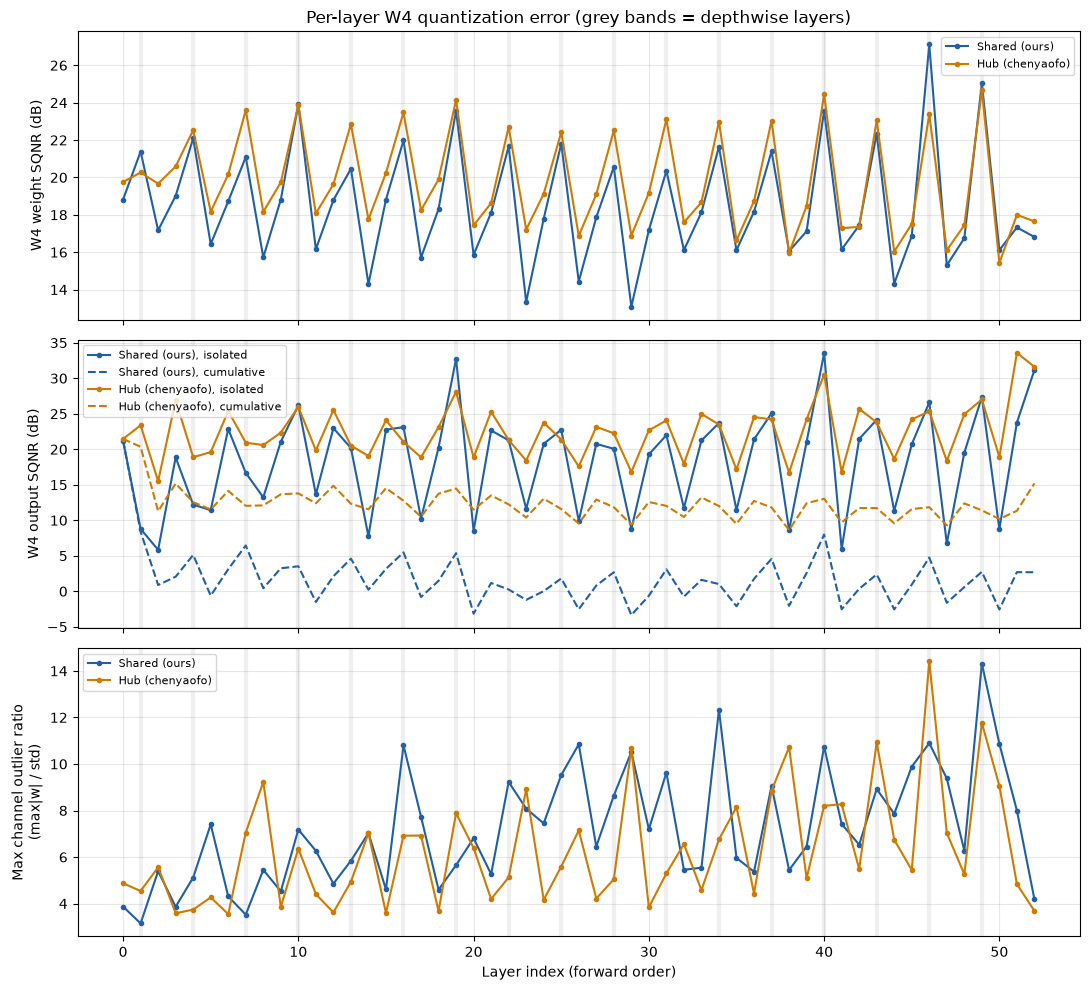

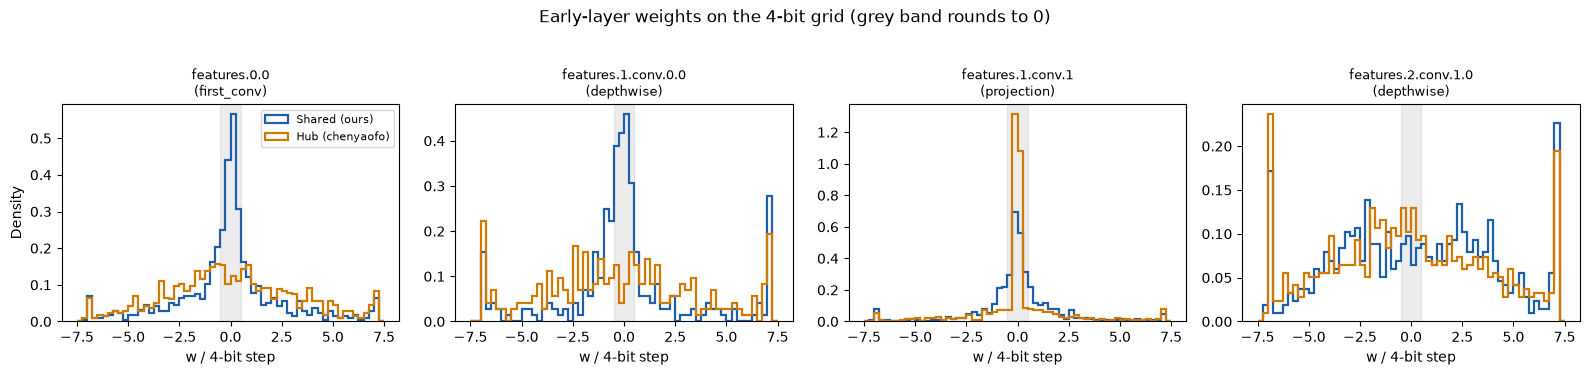

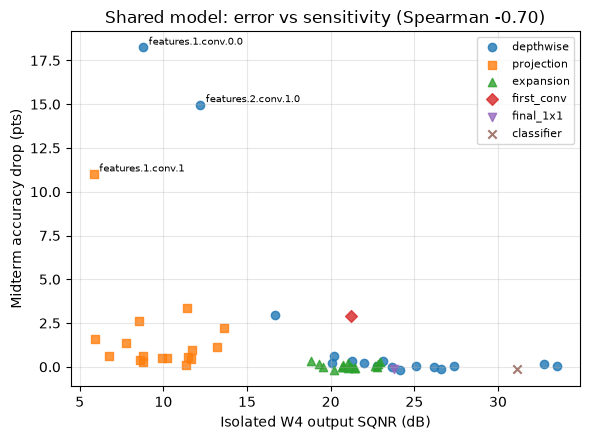

Saved to /Users/amandanemshin/Desktop/Duke/Senior/ECE662/Layer-Wise-Quantization-of-MobileNetV2-for-Edge-Accelerators/results
['a8_results.csv', 'amanda_handoff.md', 'amanda_neurosim_configs.json', 'block_protection_results.csv', 'block_vs_topk_matched.csv', 'checkpoint_comparison.csv', 'clipping_bias_correction_results.csv', 'error_growth_by_block.csv', 'evidence_table.csv', 'fig_c2_block_vs_topk.png', 'fig_c2_error_by_block.png', 'fig_c3_pareto_a8.png', 'fig_early_weight_distributions.png', 'fig_error_vs_sensitivity.png', 'fig_layer_error_by_depth.png', 'layer_quantization_error.csv', 'layer_weight_stats.csv', 'pareto_frontier_a8.csv', 'relu6_saturation.csv', 'retrain_comparison.csv', 'slide_1_where_it_breaks.png', 'slide_2_fixes_and_cost.png', 'topk_curve.csv', 'w4_region_results.csv']


In [25]:
colors = {"Shared (ours)": "#1f5fa8", "Hub (chenyaofo)": "#d17a00"}

# Figure 1: per-layer metrics across depth
fig, axes = plt.subplots(3, 1, figsize=(11, 10), sharex=True)
for model_name, color in colors.items():
    ws = layer_weight_stats[layer_weight_stats["Model"] == model_name]
    er = layer_quantization_error[layer_quantization_error["Model"] == model_name]
    axes[0].plot(ws["Index"], ws["W4 weight SQNR (dB)"], marker="o", ms=3, color=color, label=model_name)
    axes[1].plot(er["Index"], er["Isolated W4 output SQNR (dB)"], marker="o", ms=3, color=color,
                 label=f"{model_name}, isolated")
    axes[1].plot(er["Index"], er["Cumulative W4 output SQNR (dB)"], ls="--", color=color,
                 label=f"{model_name}, cumulative")
    axes[2].plot(ws["Index"], ws["Outlier ratio (max)"], marker="o", ms=3, color=color, label=model_name)

axes[0].set_ylabel("W4 weight SQNR (dB)")
axes[1].set_ylabel("W4 output SQNR (dB)")
axes[2].set_ylabel("Max channel outlier ratio\n(max|w| / std)")
axes[2].set_xlabel("Layer index (forward order)")
for ax in axes:
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
depthwise_idx = layer_weight_stats[(layer_weight_stats["Model"] == "Shared (ours)") &
                                   (layer_weight_stats["Type"] == "depthwise")]["Index"]
for ax in axes:
    for i in depthwise_idx:
        ax.axvline(i, color="grey", alpha=0.12, lw=3)
axes[0].set_title("Per-layer W4 quantization error (grey bands = depthwise layers)")
fig.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "fig_layer_error_by_depth.png"), dpi=200)
plt.show()

# Figure 2: early-layer weight distributions in units of the 4-bit step (w / per-channel scale)
early_layers = ["features.0.0", "features.1.conv.0.0", "features.1.conv.1", "features.2.conv.1.0"]
fig, axes = plt.subplots(1, len(early_layers), figsize=(16, 3.6))
for ax, layer_name in zip(axes, early_layers):
    for model_name, model in [("Shared (ours)", folded_baseline), ("Hub (chenyaofo)", hub_folded)]:
        w = dict(model.named_modules())[layer_name].weight.detach().float().cpu()
        w_flat = w.reshape(w.shape[0], -1)
        scale = w_flat.abs().amax(dim=1, keepdim=True).clamp_min(1e-12) / 7
        ax.hist((w_flat / scale).reshape(-1).numpy(), bins=np.arange(-7.5, 7.6, 0.25), density=True,
                histtype="step", lw=1.6, color=colors[model_name], label=model_name)
    ax.axvspan(-0.5, 0.5, color="grey", alpha=0.15)
    ax.set_title(f"{layer_name}\n({layer_type(layer_name, dict(folded_baseline.named_modules())[layer_name])})",
                 fontsize=9)
    ax.set_xlabel("w / 4-bit step")
axes[0].set_ylabel("Density")
axes[0].legend(fontsize=8)
fig.suptitle("Early-layer weights on the 4-bit grid (grey band rounds to 0)", y=1.03)
fig.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "fig_early_weight_distributions.png"), dpi=200, bbox_inches="tight")
plt.show()

# Figure 3: does isolated output error track the midterm accuracy sensitivity?
fig, ax = plt.subplots(figsize=(6, 4.5))
for layer_kind, marker in [("depthwise", "o"), ("projection", "s"), ("expansion", "^"),
                           ("first_conv", "D"), ("final_1x1", "v"), ("classifier", "x")]:
    d = valid[valid["Type"] == layer_kind]
    ax.scatter(d["Isolated W4 output SQNR (dB)"], d["Midterm sensitivity drop (pts)"], marker=marker,
               label=layer_kind, alpha=0.8)
for _, r in valid.nlargest(3, "Midterm sensitivity drop (pts)").iterrows():
    ax.annotate(r["Layer"], (r["Isolated W4 output SQNR (dB)"], r["Midterm sensitivity drop (pts)"]),
                fontsize=7, xytext=(4, 2), textcoords="offset points")
ax.set_xlabel("Isolated W4 output SQNR (dB)")
ax.set_ylabel("Midterm accuracy drop (pts)")
ax.set_title(f"Shared model: error vs sensitivity (Spearman {spearman:.2f})")
ax.grid(alpha=0.3)
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "fig_error_vs_sensitivity.png"), dpi=200)
plt.show()

print("Saved to", OUT_DIR)
print(sorted(f for f in os.listdir(OUT_DIR)))

## How to read these results (notes for the INT4 Failure Investigation section)

Fill in after running. Keep each item labeled as **demonstrated**, **ruled out**, or **hypothesis**.

1. **Same quantizer, different outcome:** do the two models still differ at W4 (`checkpoint_comparison.csv`)?
2. **Structure:** the models share layer names and shapes but differ in stride at `features.0.0` and
   `features.2.conv.1.0`, so their early feature maps and final map size differ. Resolution and architecture
   are therefore confounded with training: an observation, not yet a cause.
3. **Weights:** are outlier ratios / zero fractions / W4 weight SQNR worse in the shared model's early layers?
   If yes, that supports the outlier hypothesis. Checkpoint 2's clipping test checks it directly.
4. **Local vs compounding error:** compare isolated and cumulative SQNR through blocks 0–3. Large error growth
   supports compounding. Protecting whole blocks (Checkpoint 2) tests it directly.
5. **Activations:** large input outlier ratios or channel spreads flag layers that will also be hard at A8.
   These do not explain the weight-only collapse, but they matter for the A8 rerun.

# Checkpoint 2 (Nov 11–17): Block protection, compounding, and clipping

Run this after the Checkpoint 1 section (it reuses its models and helpers).

Experiments:
1. **Whole-block protection:** keep the first conv and the first few inverted-residual blocks entirely at W8,
   everything else at W4.
2. **Block vs top-k at matched storage:** compare each block config with the top-k config (midterm validation
   ranking) whose weight storage is closest.
3. **Where does the damage come from?** W4 only in the early blocks vs W4 only in the later blocks.
4. **Compounding summary:** error growth by block from Checkpoint 1.
5. **Clipping test:** replace the max-based scale with an MSE-optimal clip. If W4 recovers, outlier weights are
   the cause.
6. **Bias-correction test:** subtract each channel's average output shift caused by weight rounding. If W4
   recovers, most of the damage is a systematic offset rather than random noise (this tests the smooth-input
   hypothesis from Checkpoint 1).

Fairness rules: block configs are chosen from the architecture, not from test results; top-k uses the midterm
**validation** ranking; clipping and bias correction are calibrated on **training** images. The test set is only
used for reporting accuracy. Activations stay FP32 (Checkpoint 3 reruns the key configs at A8).

Outputs: `block_protection_results.csv`, `topk_curve.csv`, `w4_region_results.csv`,
`clipping_bias_correction_results.csv`, `error_growth_by_block.csv`, figures `fig_c2_*.png`.

In [26]:
# ---- Checkpoint 2 helpers ----
shared_names = [n for n, _ in eligible_layers_of(folded_baseline)]
shared_modules = dict(folded_baseline.named_modules())


def quantize_config(model, config, quantizer=None):
    """Fresh copy with each layer quantized to config[name] bits (all eligible layers must be listed)."""
    quantizer = quantizer or quantize_weights
    names = [n for n, _ in eligible_layers_of(model)]
    assert set(config) == set(names), "config must list every eligible layer"
    q_model = copy.deepcopy(model).eval()
    with torch.no_grad():
        for name, layer in q_model.named_modules():
            if name in config:
                layer.weight.copy_(quantizer(layer.weight, config[name]))
    return q_model


def storage_mb(model, config):
    """Weight payload (midterm definition) and a deployed estimate that adds per-channel FP32 scales and FP32
    biases (every conv has a bias after BN folding). Josie's calculator is the authoritative version."""
    modules = dict(model.named_modules())
    payload_bits = 0
    overhead_bits = 0
    for name, bits in config.items():
        layer = modules[name]
        payload_bits += layer.weight.numel() * bits
        out_channels = layer.weight.shape[0]
        overhead_bits += out_channels * 32                      # per-channel scale
        overhead_bits += (out_channels * 32) if layer.bias is not None else 0
    return payload_bits / 8 / 1e6, (payload_bits + overhead_bits) / 8 / 1e6


def config_protecting(names, protected):
    return {n: 8 if n in protected else 4 for n in names}


def blocks_config(names, blocks_at_8):
    return {n: 8 if block_of(n) in blocks_at_8 else 4 for n in names}


ranked_layers = pd.read_csv(os.path.join(REPO_DIR, "layer_sensitivity_ranking.csv"))["Layer"].tolist()
assert set(ranked_layers) == set(shared_names)

w8_reference = folded_w8_accuracy   # 89.87 from the sanity check
print(f"W8 reference accuracy: {w8_reference:.2f}% | 1-point target: {w8_reference - 1:.2f}%")

W8 reference accuracy: 89.87% | 1-point target: 88.87%


## C2.1: Whole-block protection

Block 0 = first conv, blocks 1–17 = inverted residuals (`features.N`), 18 = final 1×1, 19 = classifier.

In [27]:
block_sets = {
    "Block 1 only": {1},
    "Blocks 0-1": {0, 1},
    "Blocks 1-2": {1, 2},
    "Blocks 0-2": {0, 1, 2},
    "Blocks 0-3": {0, 1, 2, 3},
    "Blocks 0-4": {0, 1, 2, 3, 4},
    "Blocks 0-5": {0, 1, 2, 3, 4, 5},
    "Blocks 0-7": set(range(0, 8)),
}

block_rows = []
for label, blocks in block_sets.items():
    config = blocks_config(shared_names, blocks)
    accuracy = evaluate(quantize_config(folded_baseline, config), test_loader)
    payload, deployed = storage_mb(folded_baseline, config)
    block_rows.append({
        "Method": "Whole blocks", "Config": label,
        "Layers at W8": sum(b == 8 for b in config.values()),
        "Test accuracy (%)": accuracy, "Gap to W8 (pts)": w8_reference - accuracy,
        "Weight payload (MB)": payload, "Deployed estimate (MB)": deployed,
    })
    print(f"{label:<14} {accuracy:6.2f}% | {payload:.3f} MB payload", flush=True)

block_results = pd.DataFrame(block_rows)
display(block_results.round(3))

Block 1 only    42.01% | 1.102 MB payload
Blocks 0-1      49.42% | 1.102 MB payload
Blocks 1-2      60.22% | 1.104 MB payload
Blocks 0-2      65.93% | 1.104 MB payload
Blocks 0-3      70.10% | 1.109 MB payload
Blocks 0-4      75.17% | 1.113 MB payload
Blocks 0-5      79.58% | 1.120 MB payload
Blocks 0-7      82.39% | 1.137 MB payload


,Method,Config,Layers at W8,Test accuracy (%),Gap to W8 (pts),Weight payload (MB),Deployed estimate (MB)
0,Whole blocks,Block 1 only,2,42.01,47.86,1.102,1.238
1,Whole blocks,Blocks 0-1,3,49.42,40.45,1.102,1.239
2,Whole blocks,Blocks 1-2,5,60.22,29.65,1.104,1.241
3,Whole blocks,Blocks 0-2,6,65.93,23.94,1.104,1.241
4,Whole blocks,Blocks 0-3,9,70.10,19.77,1.109,1.245
5,Whole blocks,Blocks 0-4,12,75.17,14.70,1.113,1.250
6,Whole blocks,Blocks 0-5,15,79.58,10.29,1.120,1.257
7,Whole blocks,Blocks 0-7,21,82.39,7.48,1.137,1.274


## C2.2: Top-k curve and block vs top-k at matched storage

Evaluates every k from 0 to 53 (top-k layers by the midterm validation ranking at W8, rest at W4). About 3 s per
config on the Mac GPU.

In [28]:
topk_rows = []
for k in range(0, len(ranked_layers) + 1):
    config = config_protecting(shared_names, set(ranked_layers[:k]))
    accuracy = evaluate(quantize_config(folded_baseline, config), test_loader)
    payload, deployed = storage_mb(folded_baseline, config)
    topk_rows.append({
        "Method": "Top-k", "Config": f"Top-{k}", "k": k, "Layers at W8": k,
        "Test accuracy (%)": accuracy, "Gap to W8 (pts)": w8_reference - accuracy,
        "Weight payload (MB)": payload, "Deployed estimate (MB)": deployed,
    })
    if k % 5 == 0:
        print(f"k={k:2d}: {accuracy:6.2f}% | {payload:.3f} MB", flush=True)

topk_curve = pd.DataFrame(topk_rows)
topk_curve.to_csv(os.path.join(OUT_DIR, "topk_curve.csv"), index=False)

within_one = topk_curve[topk_curve["Gap to W8 (pts)"] <= 1.0]
if len(within_one):
    best = within_one.iloc[0]
    print(f"\nSmallest k within 1 point of W8: k={int(best['k'])} "
          f"({best['Test accuracy (%)']:.2f}%, {best['Weight payload (MB)']:.3f} MB)")
else:
    print("\nNo k reaches within 1 point of W8.")

# Pair each block config with the top-k whose weight payload is closest
matched_rows = []
for _, block_row in block_results.iterrows():
    nearest = topk_curve.iloc[(topk_curve["Weight payload (MB)"] - block_row["Weight payload (MB)"]).abs().argmin()]
    matched_rows.append({
        "Block config": block_row["Config"],
        "Block accuracy (%)": block_row["Test accuracy (%)"],
        "Block payload (MB)": block_row["Weight payload (MB)"],
        "Matched top-k": nearest["Config"],
        "Top-k accuracy (%)": nearest["Test accuracy (%)"],
        "Top-k payload (MB)": nearest["Weight payload (MB)"],
        "Block minus top-k (pts)": block_row["Test accuracy (%)"] - nearest["Test accuracy (%)"],
    })
block_vs_topk = pd.DataFrame(matched_rows)

block_protection_results = pd.concat([block_results, topk_curve.drop(columns="k")], ignore_index=True)
block_protection_results.to_csv(os.path.join(OUT_DIR, "block_protection_results.csv"), index=False)
block_vs_topk.to_csv(os.path.join(OUT_DIR, "block_vs_topk_matched.csv"), index=False)
display(block_vs_topk.round(3))

k= 0:  17.58% | 1.101 MB
k= 5:  63.99% | 1.104 MB
k=10:  79.88% | 1.162 MB
k=15:  83.44% | 1.413 MB
k=20:  86.62% | 1.496 MB
k=25:  87.57% | 1.515 MB
k=30:  88.62% | 1.534 MB
k=35:  89.34% | 1.638 MB
k=40:  89.25% | 1.651 MB
k=45:  89.50% | 1.848 MB
k=50:  89.70% | 2.189 MB

Smallest k within 1 point of W8: k=32 (89.08%, 1.612 MB)


,Block config,Block accuracy (%),Block payload (MB),Matched top-k,Top-k accuracy (%),Top-k payload (MB),Block minus top-k (pts)
0,Block 1 only,42.01,1.102,Top-2,41.52,1.102,0.49
1,Blocks 0-1,49.42,1.102,Top-3,58.91,1.102,-9.49
2,Blocks 1-2,60.22,1.104,Top-5,63.99,1.104,-3.77
3,Blocks 0-2,65.93,1.104,Top-6,69.77,1.104,-3.84
4,Blocks 0-3,70.10,1.109,Top-7,73.95,1.110,-3.85
5,Blocks 0-4,75.17,1.113,Top-8,76.70,1.113,-1.53
6,Blocks 0-5,79.58,1.120,Top-8,76.70,1.113,2.88
7,Blocks 0-7,82.39,1.137,Top-9,77.79,1.159,4.60


## C2.3: Where does the damage come from?

Put W4 in only one region of the network and keep everything else at W8. If W4 in the early blocks alone
collapses accuracy, early-layer error is enough to cause the collapse.

In [29]:
regions = {
    "W4 only in blocks 0-1": {0, 1},
    "W4 only in blocks 0-3": {0, 1, 2, 3},
    "W4 only in blocks 4-10": set(range(4, 11)),
    "W4 only in blocks 11-17": set(range(11, 18)),
    "W4 only in blocks 4-19": set(range(4, 20)),
    "W4 only in blocks 18-19": {18, 19},
}
region_rows = []
for label, blocks in regions.items():
    config = {n: 4 if block_of(n) in blocks else 8 for n in shared_names}
    accuracy = evaluate(quantize_config(folded_baseline, config), test_loader)
    region_rows.append({
        "Config": label, "Layers at W4": sum(b == 4 for b in config.values()),
        "Test accuracy (%)": accuracy, "Drop from W8 (pts)": w8_reference - accuracy,
    })
    print(f"{label:<24} {accuracy:6.2f}%", flush=True)
w4_region_results = pd.DataFrame(region_rows)
w4_region_results.to_csv(os.path.join(OUT_DIR, "w4_region_results.csv"), index=False)
display(w4_region_results.round(2))

W4 only in blocks 0-1     51.75%
W4 only in blocks 0-3     18.00%
W4 only in blocks 4-10    76.18%
W4 only in blocks 11-17   85.10%
W4 only in blocks 4-19    70.10%
W4 only in blocks 18-19   89.92%


,Config,Layers at W4,Test accuracy (%),Drop from W8 (pts)
0,W4 only in blocks 0-1,3,51.75,38.12
1,W4 only in blocks 0-3,9,18.00,71.87
2,W4 only in blocks 4-10,21,76.18,13.69
3,W4 only in blocks 11-17,21,85.10,4.77
4,W4 only in blocks 4-19,44,70.10,19.77
5,W4 only in blocks 18-19,2,89.92,-0.05


## C2.4: Error compounding by block

From the Checkpoint 1 measurements: for each block, the isolated SQNR of its worst layer (error the block adds by
itself) and the cumulative SQNR at the block's last layer (error that has built up by then). In a network where
errors simply add, cumulative SQNR would track the worst isolated SQNR so far; much lower values mean compounding.

In [30]:
error_df = pd.read_csv(os.path.join(OUT_DIR, "layer_quantization_error.csv"))
growth_rows = []
for model_name, d in error_df.groupby("Model"):
    d = d.sort_values("Index")
    running_worst = float("inf")
    for block, b in d.groupby("Block", sort=True):
        worst_isolated = b["Isolated W4 output SQNR (dB)"].min()
        running_worst = min(running_worst, worst_isolated)
        growth_rows.append({
            "Model": model_name, "Block": block,
            "Worst isolated SQNR in block (dB)": worst_isolated,
            "Worst isolated SQNR so far (dB)": running_worst,
            "Cumulative SQNR at block output (dB)": b.iloc[-1]["Cumulative W4 output SQNR (dB)"],
        })
error_growth = pd.DataFrame(growth_rows)
error_growth["Compounding (dB)"] = (error_growth["Worst isolated SQNR so far (dB)"]
                                    - error_growth["Cumulative SQNR at block output (dB)"])
error_growth.to_csv(os.path.join(OUT_DIR, "error_growth_by_block.csv"), index=False)
display(error_growth.pivot(index="Block", columns="Model",
                           values=["Cumulative SQNR at block output (dB)", "Compounding (dB)"]).round(2))

Cumulative SQNR at block output (dB)               Compounding (dB)  \
Model                      Hub (chenyaofo) Shared (ours)  Hub (chenyaofo)   
Block                                                                       
0                                    21.45         21.22             0.00   
1                                    11.28          0.88             4.23   
2                                    11.53         -0.61             3.98   
3                                    12.10          0.42             3.42   
4                                    12.39         -1.50             3.12   
5                                    11.54          0.23             3.97   
6                                    10.50         -0.81             5.02   
7                                    11.50         -3.15             4.01   
8                                    10.39         -1.20             5.12   
9                                     9.56         -2.52             5.96   
10                                    9.38         -3.34             6.13   
11                                   10.46         -0.74             5.05   
12                                    9.49         -2.11             6.02   
13                                    8.62         -2.05             6.89   
14                                    9.70         -2.53             5.81   
15                                    9.58         -2.55             5.94   
16                                    9.27         -1.62             6.24   
17                                   10.18         -2.56             5.33   
18                                   11.34          2.70             4.18   
19                                   15.19          2.68             0.32   

                     
Model Shared (ours)  
Block                
0              0.00  
1              4.96  
2              6.45  
3              5.42  
4              7.34  
5              5.61  
6              6.65  
7              8.99  
8              7.04  
9              8.36  
10             9.18  
11             6.58  
12             7.95  
13             7.89  
14             8.37  
15             8.39  
16             7.46  
17             8.40  
18             3.14  
19             3.15

## C2.5: Clipping test and bias-correction test

- **MSE clip:** for each output channel, search clip values from 30% to 100% of max|w| and keep the one with the
  smallest weight rounding error. This trades clipped outliers for finer steps.
- **Bias correction:** with 512 **training** images, measure each channel's average output shift caused by weight
  rounding (layer by layer, FP32 inputs) and subtract it from that channel's bias. This removes the systematic
  part of the error and leaves the random part.

In [31]:
def quantize_weights_mse(weights, bits, grid=None):
    """Per-channel symmetric quantization with the clip value chosen to minimize weight MSE."""
    grid = grid if grid is not None else np.linspace(0.30, 1.00, 36)
    qmax = (2 ** (bits - 1)) - 1
    flat = weights.reshape(weights.shape[0], -1)
    max_abs = flat.abs().amax(dim=1, keepdim=True)
    best, best_error = None, None
    for fraction in grid:
        scale = torch.where(max_abs > 0, float(fraction) * max_abs / qmax, torch.ones_like(max_abs))
        q = torch.clamp(torch.round(flat / scale), -qmax, qmax) * scale
        error = ((q - flat) ** 2).sum(dim=1, keepdim=True)
        if best is None:
            best, best_error = q, error
        else:
            better = error < best_error
            best = torch.where(better, q, best)
            best_error = torch.where(better, error, best_error)
    return best.reshape(weights.shape)


def calibration_loader(transform, n_images=512):
    """Training images only (outside the 5,000-image validation split used for the sensitivity ranking)."""
    train_dataset = datasets.CIFAR10(root=DATA_DIR, train=True, download=True, transform=transform)
    order = torch.randperm(len(train_dataset), generator=torch.Generator().manual_seed(42))
    calib_indices = order[:45000][:n_images].tolist()
    return DataLoader(Subset(train_dataset, calib_indices), batch_size=ANALYSIS_BATCH, shuffle=False,
                      num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY)


@torch.inference_mode()
def apply_bias_correction(fp32_model, q_model, loader):
    """Empirical per-channel bias correction (layer by layer, using FP32 inputs)."""
    names = [n for n, _ in eligible_layers_of(fp32_model)]
    q_modules = dict(q_model.named_modules())
    fp_modules = dict(fp32_model.named_modules())
    sums = {n: None for n in names}
    counts = {n: 0 for n in names}
    model_device = next(fp32_model.parameters()).device

    for images, _ in loader:
        store = {}
        hooks = [fp_modules[n].register_forward_hook(
            lambda m, i, o, n=n: store.__setitem__(n, (i[0].clone(), o.clone()))) for n in names]
        fp32_model(images.to(model_device))
        for h in hooks:
            h.remove()
        for n in names:
            x, ref = store[n]
            diff = q_modules[n](x) - ref
            dims = (0, 2, 3) if diff.ndim == 4 else (0,)
            channel_sum = diff.sum(dim=dims)
            sums[n] = channel_sum if sums[n] is None else sums[n] + channel_sum
            counts[n] += diff.numel() // diff.shape[1]

    corrected = copy.deepcopy(q_model).eval()
    corrected_modules = dict(corrected.named_modules())
    for n in names:
        layer = corrected_modules[n]
        shift = sums[n] / counts[n]
        if layer.bias is None:
            layer.bias = nn.Parameter(torch.zeros(layer.weight.shape[0], device=layer.weight.device))
        layer.bias.data -= shift.to(layer.bias.dtype)
    return corrected


shared_calib = calibration_loader(transform)
hub_calib = calibration_loader(hub_transform)

top10_config = config_protecting(shared_names, set(ranked_layers[:10]))
blocks02_config = blocks_config(shared_names, block_sets["Blocks 0-2"])
all_w4_shared = {n: 4 for n in shared_names}
all_w4_hub = {n: 4 for n, _ in eligible_layers_of(hub_folded)}

clip_rows = []
experiments = [
    ("Shared (ours)", "Uniform W4", folded_baseline, all_w4_shared, test_loader, shared_calib),
    ("Shared (ours)", "Top-10", folded_baseline, top10_config, test_loader, shared_calib),
    ("Shared (ours)", "Blocks 0-2 at W8", folded_baseline, blocks02_config, test_loader, shared_calib),
    ("Hub (chenyaofo)", "Uniform W4", hub_folded, all_w4_hub, hub_test_loader, hub_calib),
]
for model_name, config_name, base, config, loader, calib in experiments:
    for clip_name, quantizer in [("Max scale", quantize_weights), ("MSE clip", quantize_weights_mse)]:
        q_model = quantize_config(base, config, quantizer)
        plain = evaluate(q_model, loader)
        corrected = evaluate(apply_bias_correction(base, q_model, calib), loader)
        clip_rows.append({
            "Model": model_name, "Config": config_name, "Scale": clip_name,
            "Accuracy (%)": plain, "Accuracy with bias correction (%)": corrected,
            "Bias-correction gain (pts)": corrected - plain,
        })
        print(f"{model_name:<16} {config_name:<17} {clip_name:<9} {plain:6.2f}% -> {corrected:6.2f}% "
              f"with bias correction", flush=True)

clip_results = pd.DataFrame(clip_rows)
clip_results.to_csv(os.path.join(OUT_DIR, "clipping_bias_correction_results.csv"), index=False)
display(clip_results.round(2))

# Weight-level effect of MSE clipping (shared model, uniform W4)
mse_gain = []
for name in shared_names:
    w = shared_modules[name].weight.detach().float().cpu()
    signal = (w ** 2).sum().item()
    max_sqnr = sqnr_db(signal, ((quantize_weights(w, 4) - w) ** 2).sum().item())
    mse_sqnr = sqnr_db(signal, ((quantize_weights_mse(w, 4) - w) ** 2).sum().item())
    mse_gain.append(mse_sqnr - max_sqnr)
print(f"MSE clip improves W4 weight SQNR by {np.mean(mse_gain):.2f} dB on average "
      f"(range {np.min(mse_gain):.2f} to {np.max(mse_gain):.2f} dB) in the shared model.")

Shared (ours)    Uniform W4        Max scale  17.58% ->  77.22% with bias correction
Shared (ours)    Uniform W4        MSE clip   20.86% ->  74.49% with bias correction
Shared (ours)    Top-10            Max scale  79.88% ->  87.42% with bias correction
Shared (ours)    Top-10            MSE clip   60.85% ->  87.16% with bias correction
Shared (ours)    Blocks 0-2 at W8  Max scale  65.93% ->  85.95% with bias correction
Shared (ours)    Blocks 0-2 at W8  MSE clip   46.82% ->  86.14% with bias correction
Hub (chenyaofo)  Uniform W4        Max scale  92.84% ->  93.06% with bias correction
Hub (chenyaofo)  Uniform W4        MSE clip   91.80% ->  93.21% with bias correction


,Model,Config,Scale,Accuracy (%),Accuracy with bias correction (%),Bias-correction gain (pts)
0,Shared (ours),Uniform W4,Max scale,17.58,77.22,59.64
1,Shared (ours),Uniform W4,MSE clip,20.86,74.49,53.63
2,Shared (ours),Top-10,Max scale,79.88,87.42,7.54
3,Shared (ours),Top-10,MSE clip,60.85,87.16,26.31
4,Shared (ours),Blocks 0-2 at W8,Max scale,65.93,85.95,20.02
5,Shared (ours),Blocks 0-2 at W8,MSE clip,46.82,86.14,39.32
6,Hub (chenyaofo),Uniform W4,Max scale,92.84,93.06,0.22
7,Hub (chenyaofo),Uniform W4,MSE clip,91.80,93.21,1.41


MSE clip improves W4 weight SQNR by 0.90 dB on average (range 0.13 to 2.73 dB) in the shared model.


## C2.6: Figures

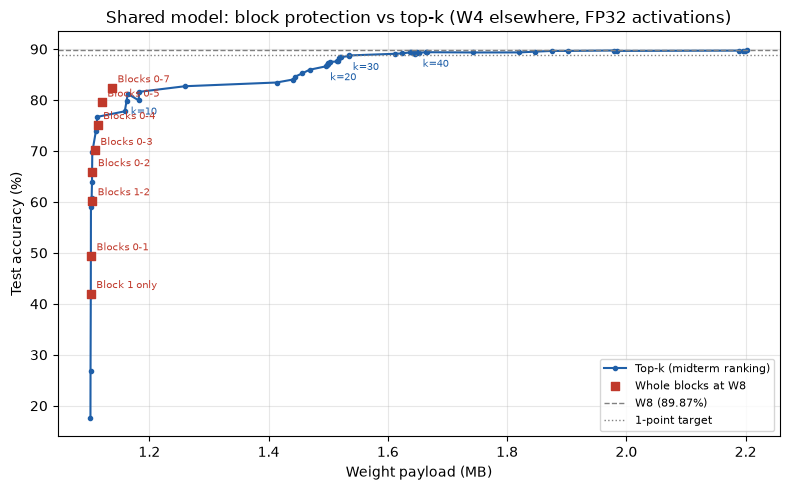

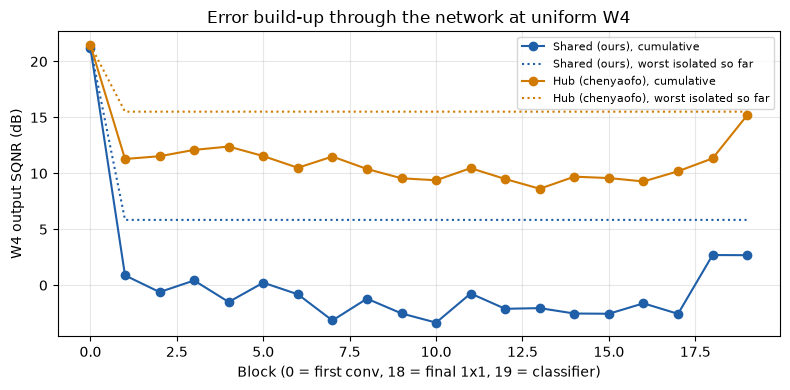

Saved: ['block_protection_results.csv', 'block_vs_topk_matched.csv', 'clipping_bias_correction_results.csv', 'error_growth_by_block.csv', 'fig_c2_block_vs_topk.png', 'fig_c2_error_by_block.png', 'topk_curve.csv', 'w4_region_results.csv']


In [32]:
# Figure 1: accuracy vs weight storage: top-k curve, block configs, W8/W4 references
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(topk_curve["Weight payload (MB)"], topk_curve["Test accuracy (%)"], marker="o", ms=3,
        color="#1f5fa8", label="Top-k (midterm ranking)")
for _, r in topk_curve[topk_curve["k"].isin([10, 20, 30, 40])].iterrows():
    ax.annotate(f"k={int(r['k'])}", (r["Weight payload (MB)"], r["Test accuracy (%)"]), fontsize=7,
                xytext=(3, -10), textcoords="offset points", color="#1f5fa8")
ax.scatter(block_results["Weight payload (MB)"], block_results["Test accuracy (%)"], marker="s", s=40,
           color="#c0392b", zorder=3, label="Whole blocks at W8")
for _, r in block_results.iterrows():
    ax.annotate(r["Config"], (r["Weight payload (MB)"], r["Test accuracy (%)"]), fontsize=7,
                xytext=(4, 4), textcoords="offset points", color="#c0392b")
ax.axhline(w8_reference, color="grey", ls="--", lw=1, label=f"W8 ({w8_reference:.2f}%)")
ax.axhline(w8_reference - 1, color="grey", ls=":", lw=1, label="1-point target")
ax.set_xlabel("Weight payload (MB)")
ax.set_ylabel("Test accuracy (%)")
ax.set_title("Shared model: block protection vs top-k (W4 elsewhere, FP32 activations)")
ax.grid(alpha=0.3)
ax.legend(fontsize=8, loc="lower right")
fig.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "fig_c2_block_vs_topk.png"), dpi=200)
plt.show()

# Figure 2: cumulative SQNR by block, both models
fig, ax = plt.subplots(figsize=(8, 4))
for model_name, color in colors.items():
    d = error_growth[error_growth["Model"] == model_name]
    ax.plot(d["Block"], d["Cumulative SQNR at block output (dB)"], marker="o", color=color,
            label=f"{model_name}, cumulative")
    ax.plot(d["Block"], d["Worst isolated SQNR so far (dB)"], ls=":", color=color,
            label=f"{model_name}, worst isolated so far")
ax.set_xlabel("Block (0 = first conv, 18 = final 1x1, 19 = classifier)")
ax.set_ylabel("W4 output SQNR (dB)")
ax.set_title("Error build-up through the network at uniform W4")
ax.grid(alpha=0.3)
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "fig_c2_error_by_block.png"), dpi=200)
plt.show()

print("Saved:", sorted(f for f in os.listdir(OUT_DIR) if f.startswith(("fig_c2", "block", "topk", "w4_", "clipping", "error_growth"))))

## How to read Checkpoint 2 (notes for the report)

1. **Block vs top-k:** positive "Block minus top-k" means whole-block protection beats layer-wise top-k at the
   same storage. Note which configs come within 1 point of W8, if any.
2. **Region test:** if "W4 only in blocks 0-1" or "0-3" alone drops accuracy sharply while later regions do not,
   the early layers are sufficient to cause the collapse.
3. **Compounding:** large positive "Compounding (dB)" in early blocks means errors grow faster than the worst
   single layer would predict.
4. **Clipping:** a big gain from MSE clip supports the outlier hypothesis; little gain weakens it.
5. **Bias correction:** a big gain means the damage is mostly a systematic per-channel offset. That is consistent
   with the smooth-input hypothesis, but the 32×32 retrain (Checkpoint 3) is the direct test.

# Checkpoint 3 (Nov 18–24): A8 reruns, retrained variants, and the evidence table

Run this after Checkpoints 1 and 2.

1. **Fixed A8 activations.** The professor's top request: accuracy and NeuroSim must use the same activation
   precision. Every key config is re-evaluated with 8-bit activations. `ACT_QUANT_SOURCE` is the one switch:
   `"amanda"` uses the A8 quantizer below; once Lilly's shared A8 quantizer is ready, set it to `"lilly"` and
   paste her function into `lilly_activation_quantizer`, then rerun this section. Confirm with Lilly that her
   spec matches (8-bit, per-tensor, calibrated on training images) before reporting final numbers.
2. **ReLU6 saturation check** (from the Checkpoint 1 activation ranges).
3. **Pareto frontier at A8** across every config tested.
4. **Retrained variants** from `retrain_variants.py` (run it in Terminal first; this section skips any variant
   whose checkpoint is missing).
5. **Evidence table** pulling the key number for each hypothesis.

In [33]:
# ---- A8 activation quantization ----
ACTIVATION_BITS = 8
ACT_QUANT_SOURCE = "amanda"      # switch to "lilly" once her quantizer is pasted below


def lilly_activation_quantizer(model, calib_loader, bits):
    """Paste Lilly's shared A8 function here (must return a model whose eligible-layer inputs are quantized)."""
    raise NotImplementedError("Paste Lilly's activation quantizer here, then set ACT_QUANT_SOURCE = 'lilly'")


class InputFakeQuant:
    """Per-tensor asymmetric fake quantization of a layer's input, with min/max calibrated on training images."""

    def __init__(self, low, high, bits):
        self.bits = bits
        levels = 2 ** bits - 1
        self.scale = max((high - low) / levels, 1e-8)
        self.zero_point = round(-low / self.scale)
        self.levels = levels

    def __call__(self, module, inputs):
        x = inputs[0]
        q = torch.clamp(torch.round(x / self.scale) + self.zero_point, 0, self.levels)
        return ((q - self.zero_point) * self.scale,) + tuple(inputs[1:])


@torch.inference_mode()
def amanda_activation_quantizer(model, calib_loader, bits=ACTIVATION_BITS):
    """Copy of `model` whose every Conv/Linear input is fake-quantized to `bits` (calibrated on calib_loader).
    Ranges are measured on the model being quantized, so they include its own weight-quantization effects."""
    q_model = copy.deepcopy(model).eval()
    modules = [(n, m) for n, m in q_model.named_modules() if isinstance(m, (nn.Conv2d, nn.Linear))]
    ranges = {n: [float("inf"), float("-inf")] for n, _ in modules}

    def record(n):
        def hook(module, inputs):
            ranges[n][0] = min(ranges[n][0], inputs[0].min().item())
            ranges[n][1] = max(ranges[n][1], inputs[0].max().item())
        return hook

    hooks = [m.register_forward_pre_hook(record(n)) for n, m in modules]
    device_ = next(q_model.parameters()).device
    for images, _ in calib_loader:
        q_model(images.to(device_))
    for h in hooks:
        h.remove()
    for n, m in modules:
        low, high = min(ranges[n][0], 0.0), max(ranges[n][1], 0.0)
        m.register_forward_pre_hook(InputFakeQuant(low, high, bits))
    return q_model


def with_activations(model, calib_loader, bits=ACTIVATION_BITS):
    if ACT_QUANT_SOURCE == "lilly":
        return lilly_activation_quantizer(model, calib_loader, bits)
    return amanda_activation_quantizer(model, calib_loader, bits)


# Sanity check: FP32 weights + A8 should stay close to FP32
fp32_a8 = evaluate(with_activations(folded_baseline, shared_calib), test_loader)
w8_a8 = evaluate(with_activations(quantize_config(folded_baseline, {n: 8 for n in shared_names}), shared_calib),
                 test_loader)
print(f"Activation quantizer: {ACT_QUANT_SOURCE} ({ACTIVATION_BITS}-bit)")
print(f"FP32 weights / A8: {fp32_a8:.2f}% (FP32: {folded_fp32_accuracy:.2f}%)")
print(f"W8 / A8:           {w8_a8:.2f}% (W8 / FP32 act: {w8_reference:.2f}%)")

Activation quantizer: amanda (8-bit)
FP32 weights / A8: 89.92% (FP32: 89.82%)
W8 / A8:           89.67% (W8 / FP32 act: 89.87%)


## C3.1: ReLU6 saturation check

Checkpoint 1 found input outlier ratios of exactly 1.00 in the shared model, meaning the largest input equals
the 99.9th percentile. This measures what fraction of each layer's input sits at ReLU6's cap of 6.

In [34]:
@torch.inference_mode()
def saturation_fraction(model, loader, cap=6.0, tol=1e-4):
    names = [n for n, _ in eligible_layers_of(model)]
    modules = dict(model.named_modules())
    at_cap = {n: 0 for n in names}
    total = {n: 0 for n in names}
    hooks = []
    for n in names:
        def hook(m, inp, n=n):
            x = inp[0]
            at_cap[n] += ((x - cap).abs() <= tol).sum().item()   # exactly at the cap, not just large
            total[n] += x.numel()
        hooks.append(modules[n].register_forward_pre_hook(hook))
    device_ = next(model.parameters()).device
    for images, _ in loader:
        model(images.to(device_))
    for h in hooks:
        h.remove()
    return {n: 100.0 * at_cap[n] / total[n] for n in names}


sat_rows = []
for model_name, model, calib in [("Shared (ours)", folded_baseline, shared_calib),
                                 ("Hub (chenyaofo)", hub_folded, hub_calib)]:
    fractions = saturation_fraction(model, calib)
    for index, (n, value) in enumerate(fractions.items()):
        sat_rows.append({"Model": model_name, "Index": index, "Layer": n, "Block": block_of(n),
                         "Type": layer_type(n, dict(model.named_modules())[n]),
                         "Input at ReLU6 cap (%)": value})
saturation = pd.DataFrame(sat_rows)
saturation.to_csv(os.path.join(OUT_DIR, "relu6_saturation.csv"), index=False)
display(saturation[saturation["Block"] <= 3].pivot_table(
    index=["Index", "Layer", "Type"], columns="Model", values="Input at ReLU6 cap (%)").round(3))
print(saturation.groupby("Model")["Input at ReLU6 cap (%)"].agg(["mean", "max"]).round(3))

,,Model,Hub (chenyaofo),Shared (ours)
Index,Layer,Type,,
0,features.0.0,first_conv,0.0,0.000
1,features.1.conv.0.0,depthwise,0.0,3.475
2,features.1.conv.1,projection,0.0,4.590
3,features.2.conv.0.0,expansion,0.0,0.001
4,features.2.conv.1.0,depthwise,0.0,3.594
5,features.2.conv.2,projection,0.0,0.039
6,features.3.conv.0.0,expansion,0.0,0.000
7,features.3.conv.1.0,depthwise,0.0,0.699
8,features.3.conv.2,projection,0.0,0.526


                  mean   max
Model                       
Hub (chenyaofo)  0.000  0.00
Shared (ours)    0.299  4.59


## C3.2: Key configs at fixed A8

Every config from Checkpoints 1–2, now with 8-bit activations. Weight payload and deployed storage are unchanged
by activation precision.

In [35]:
def a8_eval(base, config, calib, loader, quantizer=None, bias_correct=False):
    q_model = quantize_config(base, config, quantizer)
    if bias_correct:
        q_model = apply_bias_correction(base, q_model, calib)
    return evaluate(with_activations(q_model, calib), loader)


a8_rows = []


def add_a8(method, config_name, config, quantizer=None, bias_correct=False, k=None):
    accuracy = a8_eval(folded_baseline, config, shared_calib, test_loader, quantizer, bias_correct)
    payload, deployed = storage_mb(folded_baseline, config)
    a8_rows.append({
        "Method": method, "Config": config_name, "k": k,
        "Layers at W8": sum(b == 8 for b in config.values()),
        "Bias correction": bias_correct, "Scale": "MSE clip" if quantizer is quantize_weights_mse else "Max scale",
        "A8 test accuracy (%)": accuracy, "Gap to W8/A8 (pts)": w8_a8 - accuracy,
        "Weight payload (MB)": payload, "Deployed estimate (MB)": deployed,
    })
    return accuracy


add_a8("Uniform", "W8", {n: 8 for n in shared_names})
add_a8("Uniform", "W4", all_w4_shared)
add_a8("Uniform", "W4 + bias correction", all_w4_shared, bias_correct=True)
add_a8("Uniform", "W4 MSE clip", all_w4_shared, quantizer=quantize_weights_mse)
add_a8("Uniform", "W4 MSE clip + bias correction", all_w4_shared, quantizer=quantize_weights_mse, bias_correct=True)
for label, blocks in block_sets.items():
    add_a8("Whole blocks", label, blocks_config(shared_names, blocks))
    add_a8("Whole blocks + bias correction", label, blocks_config(shared_names, blocks), bias_correct=True)
print("Uniform and block configs done.", flush=True)

for k in range(0, len(ranked_layers) + 1):
    config = config_protecting(shared_names, set(ranked_layers[:k]))
    add_a8("Top-k", f"Top-{k}", config, k=k)
    if k % 10 == 0:
        print(f"Top-k at A8: k={k}", flush=True)
for k in [0, 3, 5, 10, 15, 20, 30]:
    add_a8("Top-k + bias correction", f"Top-{k}", config_protecting(shared_names, set(ranked_layers[:k])),
           bias_correct=True, k=k)

a8_results = pd.DataFrame(a8_rows)
# Unique config ID, first column: matches the keys in amanda_neurosim_configs.json so teammates' code
# (e.g. Josie's merge) can join accuracy to configs. "Config" alone repeats across methods.
a8_results.insert(0, "config", a8_results["Method"] + " | " + a8_results["Config"])
a8_results.to_csv(os.path.join(OUT_DIR, "a8_results.csv"), index=False)

hub_a8 = {
    "FP32 / A8": evaluate(with_activations(hub_folded, hub_calib), hub_test_loader),
    "W8 / A8": evaluate(with_activations(quantize_config(hub_folded, {n: 8 for n in all_w4_hub}), hub_calib),
                        hub_test_loader),
    "W4 / A8": evaluate(with_activations(quantize_config(hub_folded, all_w4_hub), hub_calib), hub_test_loader),
}
print("Hub model at A8:", {k: round(v, 2) for k, v in hub_a8.items()})

display(a8_results[a8_results["Method"] != "Top-k"].round(3))

Uniform and block configs done.
Top-k at A8: k=0
Top-k at A8: k=10
Top-k at A8: k=20
Top-k at A8: k=30
Top-k at A8: k=40
Top-k at A8: k=50
Hub model at A8: {'FP32 / A8': 93.95, 'W8 / A8': 93.93, 'W4 / A8': 92.8}


,config,Method,Config,k,Layers at W8,Bias correction,Scale,A8 test accuracy (%),Gap to W8/A8 (pts),Weight payload (MB),Deployed estimate (MB)
0,Uniform | W8,Uniform,W8,NaN,53,False,Max scale,89.67,0.00,2.203,2.339
1,Uniform | W4,Uniform,W4,NaN,0,False,Max scale,17.62,72.05,1.101,1.238
2,Uniform | W4 + bias correction,Uniform,W4 + bias correction,NaN,0,True,Max scale,77.06,12.61,1.101,1.238
3,Uniform | W4 MSE clip,Uniform,W4 MSE clip,NaN,0,False,MSE clip,20.93,68.74,1.101,1.238
4,Uniform | W4 MSE clip + bias correction,Uniform,W4 MSE clip + bias correction,NaN,0,True,MSE clip,74.38,15.29,1.101,1.238
5,Whole blocks | Block 1 only,Whole blocks,Block 1 only,NaN,2,False,Max scale,41.73,47.94,1.102,1.238
6,Whole blocks + bias correction | Block 1 only,Whole blocks + bias correction,Block 1 only,NaN,2,True,Max scale,80.89,8.78,1.102,1.238
7,Whole blocks | Blocks 0-1,Whole blocks,Blocks 0-1,NaN,3,False,Max scale,49.04,40.63,1.102,1.239
8,Whole blocks + bias correction | Blocks 0-1,Whole blocks + bias correction,Blocks 0-1,NaN,3,True,Max scale,84.85,4.82,1.102,1.239
9,Whole blocks | Blocks 1-2,Whole blocks,Blocks 1-2,NaN,5,False,Max scale,60.42,29.25,1.104,1.241


## C3.3: Pareto frontier at A8

A config is on the frontier if no other config has both higher accuracy and smaller deployed storage.

,Method,Config,Bias correction,A8 test accuracy (%),Gap to W8/A8 (pts),Weight payload (MB),Deployed estimate (MB)
2,Uniform,W4 + bias correction,True,77.06,12.61,1.101,1.238
6,Whole blocks + bias correction,Block 1 only,True,80.89,8.78,1.102,1.238
8,Whole blocks + bias correction,Blocks 0-1,True,84.85,4.82,1.102,1.239
12,Whole blocks + bias correction,Blocks 0-2,True,86.16,3.51,1.104,1.241
14,Whole blocks + bias correction,Blocks 0-3,True,86.72,2.95,1.109,1.245
16,Whole blocks + bias correction,Blocks 0-4,True,87.73,1.94,1.113,1.250
18,Whole blocks + bias correction,Blocks 0-5,True,87.84,1.83,1.120,1.257
20,Whole blocks + bias correction,Blocks 0-7,True,88.78,0.89,1.137,1.274
81,Top-k + bias correction,Top-30,True,89.12,0.55,1.534,1.671
55,Top-k,Top-34,False,89.13,0.54,1.636,1.773


W8/A8 validation accuracy: 89.92%


,Method,Config,A8 validation accuracy (%),Validation gap to W8/A8 (pts),A8 test accuracy (%),Gap to W8/A8 (pts),Deployed estimate (MB)
2,Uniform,W4 + bias correction,76.92,13.00,77.06,12.61,1.238
6,Whole blocks + bias correction,Block 1 only,80.66,9.26,80.89,8.78,1.238
5,Whole blocks,Block 1 only,41.24,48.68,41.73,47.94,1.238
8,Whole blocks + bias correction,Blocks 0-1,85.38,4.54,84.85,4.82,1.239
7,Whole blocks,Blocks 0-1,48.88,41.04,49.04,40.63,1.239
10,Whole blocks + bias correction,Blocks 1-2,82.72,7.20,82.18,7.49,1.241
9,Whole blocks,Blocks 1-2,60.46,29.46,60.42,29.25,1.241
12,Whole blocks + bias correction,Blocks 0-2,85.82,4.10,86.16,3.51,1.241
11,Whole blocks,Blocks 0-2,66.62,23.30,66.09,23.58,1.241
14,Whole blocks + bias correction,Blocks 0-3,87.00,2.92,86.72,2.95,1.245


Chosen on validation (smallest within 1 point of W8/A8): Top-k + bias correction Top-30 -> validation 89.50% (gap 0.42), test 89.12% (gap 0.55) at 1.671 MB deployed
Test-set standard error at ~89% accuracy is about 0.3 pts, so gaps within ~0.6 pts of the target are a tie, not a pass/fail.


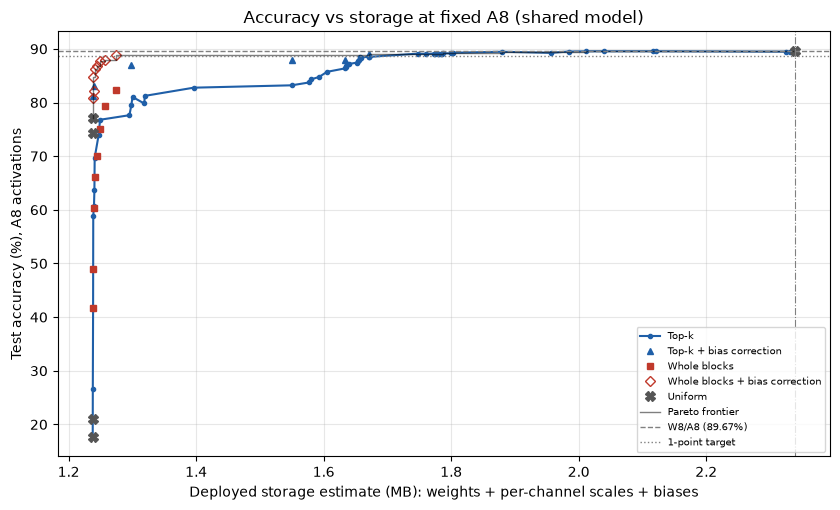

In [36]:
def pareto(df, storage_col, accuracy_col):
    ordered = df.sort_values([storage_col, accuracy_col], ascending=[True, False])
    frontier, best = [], -1.0
    for _, row in ordered.iterrows():
        if row[accuracy_col] > best:
            frontier.append(row)
            best = row[accuracy_col]
    return pd.DataFrame(frontier)


frontier = pareto(a8_results, "Deployed estimate (MB)", "A8 test accuracy (%)")
frontier.to_csv(os.path.join(OUT_DIR, "pareto_frontier_a8.csv"), index=False)
display(frontier[["Method", "Config", "Bias correction", "A8 test accuracy (%)", "Gap to W8/A8 (pts)",
                  "Weight payload (MB)", "Deployed estimate (MB)"]].round(3))

# ---- Pick the target config on the VALIDATION split, then report its test accuracy ----
# (Test accuracy is only reported, never used to choose.) Same 5,000-image split as the midterm sensitivity sweep.
def validation_loader_for(transform_, n_val=5000):
    ds = datasets.CIFAR10(root=DATA_DIR, train=True, download=True, transform=transform_)
    order = torch.randperm(len(ds), generator=torch.Generator().manual_seed(42))
    return DataLoader(Subset(ds, order[45000:45000 + n_val].tolist()), batch_size=128, shuffle=False,
                      num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY)


def config_for(method, config_name, k=None):
    base_method = method.replace(" + bias correction", "")
    if base_method == "Top-k":
        return config_protecting(shared_names, set(ranked_layers[:int(k)]))
    if base_method == "Whole blocks":
        return blocks_config(shared_names, block_sets[config_name])
    if config_name.startswith("W8"):
        return {n: 8 for n in shared_names}
    return dict(all_w4_shared)


shared_val = validation_loader_for(transform)
w8_a8_val = evaluate(with_activations(quantize_config(folded_baseline, {n: 8 for n in shared_names}), shared_calib),
                     shared_val)
candidates = pd.concat([frontier, a8_results[a8_results["Method"].str.startswith("Whole blocks")]])
candidates = candidates.drop_duplicates(subset=["Method", "Config"]).copy()
val_acc = []
for _, r in candidates.iterrows():
    quantizer = quantize_weights_mse if r["Scale"] == "MSE clip" else None
    val_acc.append(a8_eval(folded_baseline, config_for(r["Method"], r["Config"], r["k"]), shared_calib, shared_val,
                           quantizer, bool(r["Bias correction"])))
candidates["A8 validation accuracy (%)"] = val_acc
candidates["Validation gap to W8/A8 (pts)"] = w8_a8_val - candidates["A8 validation accuracy (%)"]
candidates.to_csv(os.path.join(OUT_DIR, "target_selection_validation.csv"), index=False)
print(f"W8/A8 validation accuracy: {w8_a8_val:.2f}%")
display(candidates[["Method", "Config", "A8 validation accuracy (%)", "Validation gap to W8/A8 (pts)",
                    "A8 test accuracy (%)", "Gap to W8/A8 (pts)", "Deployed estimate (MB)"]]
        .sort_values("Deployed estimate (MB)").round(3))

meets_target = candidates[candidates["Validation gap to W8/A8 (pts)"] <= 1.0].sort_values("Deployed estimate (MB)")
if len(meets_target):
    r = meets_target.iloc[0]
    print(f"Chosen on validation (smallest within 1 point of W8/A8): {r['Method']} {r['Config']} -> "
          f"validation {r['A8 validation accuracy (%)']:.2f}% (gap {r['Validation gap to W8/A8 (pts)']:.2f}), "
          f"test {r['A8 test accuracy (%)']:.2f}% (gap {r['Gap to W8/A8 (pts)']:.2f}) at "
          f"{r['Deployed estimate (MB)']:.3f} MB deployed")
    print("Test-set standard error at ~89% accuracy is about 0.3 pts, so gaps within ~0.6 pts of the target are "
          "a tie, not a pass/fail.")
else:
    print("No config is within 1 point of W8/A8 on validation: report the frontier as the negative result.")

w8_deployed = storage_mb(folded_baseline, {n: 8 for n in shared_names})[1]
fig, ax = plt.subplots(figsize=(8.5, 5.2))
styles = {
    "Top-k": dict(color="#1f5fa8", marker="o", ms=3, ls="-"),
    "Top-k + bias correction": dict(color="#1f5fa8", marker="^", ms=5, ls="none"),
    "Whole blocks": dict(color="#c0392b", marker="s", ms=5, ls="none"),
    "Whole blocks + bias correction": dict(color="#c0392b", marker="D", ms=5, ls="none", mfc="none"),
    "Uniform": dict(color="#555555", marker="X", ms=7, ls="none"),
}
for method, style in styles.items():
    d = a8_results[a8_results["Method"] == method].sort_values("Deployed estimate (MB)")
    ax.plot(d["Deployed estimate (MB)"], d["A8 test accuracy (%)"], label=method, **style)
ax.plot(frontier["Deployed estimate (MB)"], frontier["A8 test accuracy (%)"], color="black", lw=1, alpha=0.5,
        drawstyle="steps-post", label="Pareto frontier")
ax.axhline(w8_a8, color="grey", ls="--", lw=1, label=f"W8/A8 ({w8_a8:.2f}%)")
ax.axhline(w8_a8 - 1, color="grey", ls=":", lw=1, label="1-point target")
ax.axvline(w8_deployed, color="grey", ls="-.", lw=0.8)
ax.set_xlabel("Deployed storage estimate (MB): weights + per-channel scales + biases")
ax.set_ylabel("Test accuracy (%), A8 activations")
ax.set_title("Accuracy vs storage at fixed A8 (shared model)")
ax.grid(alpha=0.3)
ax.legend(fontsize=7, loc="lower right")
fig.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "fig_c3_pareto_a8.png"), dpi=200)
plt.show()

## C3.4: Retrained variants (resolution, architecture, training seed, training length)

First run in Terminal from the repo folder (with the venv active), one at a time:
```
python retrain_variants.py --variant res32_cifar_strides
python retrain_variants.py --variant res32
python retrain_variants.py --variant res64_seed1
```
Each takes roughly 20–60 minutes on the M2 Pro. This cell evaluates whichever variants exist. Every variant
uses the same quantizer, folding, A8 quantizer and bias correction as the shared model.

In [37]:
CKPT_DIR = os.path.join(REPO_DIR, "checkpoints")
variant_settings = {
    "Shared checkpoint (64x64)": {"file": CKPT_PATH, "size": 64, "cifar_strides": False},
    "res64_seed1": {"size": 64, "cifar_strides": False},
    "res32": {"size": 32, "cifar_strides": False},
    "res32_cifar_strides": {"size": 32, "cifar_strides": True},
}


def build_variant(cifar_strides):
    model = mobilenet_v2(weights=None)
    model.classifier[1] = nn.Linear(model.last_channel, 10)
    if cifar_strides:
        model.features[0][0].stride = (1, 1)
        model.features[2].conv[1][0].stride = (1, 1)
    return model


def variant_transform(size):
    resize = [transforms.Resize((size, size))] if size != 32 else []
    return transforms.Compose(resize + [transforms.ToTensor(),
                                        transforms.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225))])


def load_variant(path, cifar_strides):
    model = build_variant(cifar_strides)
    model.load_state_dict(torch.load(path, map_location="cpu", weights_only=True))
    return model.to(device).eval()


def evaluate_variant(label, path, size, cifar_strides, deep=True):
    model = load_variant(path, cifar_strides)
    folded, _ = fold_batch_norm(model)
    tfm = variant_transform(size)
    test_ds = datasets.CIFAR10(root=DATA_DIR, train=False, download=True, transform=tfm)
    loader = DataLoader(test_ds, batch_size=128, shuffle=False, num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY)
    calib = calibration_loader(tfm)
    names = [n for n, _ in eligible_layers_of(folded)]
    w4 = {n: 4 for n in names}
    row = {"Variant": label, "Input": f"{size}x{size}",
           "Strides": "CIFAR (hub-like)" if cifar_strides else "torchvision",
           "Final feature map": "x".join(map(str, final_feature_map(folded, size)))}
    row["FP32 (%)"] = evaluate(folded, loader)
    row["W8 (%)"] = evaluate(quantize_config(folded, {n: 8 for n in names}), loader)
    q4 = quantize_config(folded, w4)
    row["W4 (%)"] = evaluate(q4, loader)
    row["W4 drop (pts)"] = row["FP32 (%)"] - row["W4 (%)"]
    if deep:
        row["W4 + bias correction (%)"] = evaluate(apply_bias_correction(folded, q4, calib), loader)
        row["W8 / A8 (%)"] = evaluate(with_activations(quantize_config(folded, {n: 8 for n in names}), calib), loader)
        row["W4 / A8 (%)"] = evaluate(with_activations(q4, calib), loader)
        ws = weight_stats(folded, label)
        row["Block-1 depthwise zero fraction at W4"] = ws.loc[ws["Layer"] == "features.1.conv.0.0",
                                                              "Zero fraction at W4"].item()
        err = output_error_and_activations(folded, label, analysis_loader(test_ds))
        row["Block-1 projection cumulative W4 SQNR (dB)"] = err.loc[err["Layer"] == "features.1.conv.1",
                                                                    "Cumulative W4 output SQNR (dB)"].item()
        row["Logit cumulative W4 SQNR (dB)"] = err.sort_values("Index").iloc[-1]["Cumulative W4 output SQNR (dB)"]
    return row


variant_rows, epoch_rows = [], []
for label, s in variant_settings.items():
    path = s.get("file", os.path.join(CKPT_DIR, f"{label}_best.pth"))
    if not os.path.exists(path):
        print(f"Skipping {label}: {path} not found (run retrain_variants.py first)")
        continue
    variant_rows.append(evaluate_variant(label, path, s["size"], s["cifar_strides"]))
    print(f"{label}: FP32 {variant_rows[-1]['FP32 (%)']:.2f} | W4 {variant_rows[-1]['W4 (%)']:.2f}", flush=True)

    # Training-length sensitivity: W4 accuracy after each epoch
    epoch = 1
    while os.path.exists(os.path.join(CKPT_DIR, f"{label}_epoch{epoch}.pth")):
        r = evaluate_variant(label, os.path.join(CKPT_DIR, f"{label}_epoch{epoch}.pth"),
                             s["size"], s["cifar_strides"], deep=False)
        epoch_rows.append({"Variant": label, "Epoch": epoch, "FP32 (%)": r["FP32 (%)"], "W4 (%)": r["W4 (%)"],
                           "W4 drop (pts)": r["W4 drop (pts)"]})
        epoch += 1

retrain_comparison = pd.DataFrame(variant_rows)
retrain_comparison.to_csv(os.path.join(OUT_DIR, "retrain_comparison.csv"), index=False)
display(retrain_comparison.round(2))

epoch_sensitivity = pd.DataFrame(epoch_rows)
if len(epoch_sensitivity):
    epoch_sensitivity.to_csv(os.path.join(OUT_DIR, "epoch_sensitivity.csv"), index=False)
    fig, ax = plt.subplots(figsize=(7, 4))
    for label, d in epoch_sensitivity.groupby("Variant"):
        ax.plot(d["Epoch"], d["W4 (%)"], marker="o", label=f"{label}, W4")
        ax.plot(d["Epoch"], d["FP32 (%)"], ls=":", color=ax.lines[-1].get_color(), label=f"{label}, FP32")
    ax.set_xlabel("Training epoch")
    ax.set_ylabel("Test accuracy (%)")
    ax.set_title("Does the W4 collapse depend on training length?")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=7)
    fig.tight_layout()
    fig.savefig(os.path.join(OUT_DIR, "fig_c3_epoch_sensitivity.png"), dpi=200)
    plt.show()

Shared checkpoint (64x64): FP32 89.82 | W4 17.58
Skipping res64_seed1: /Users/amandanemshin/Desktop/Duke/Senior/ECE662/Layer-Wise-Quantization-of-MobileNetV2-for-Edge-Accelerators/checkpoints/res64_seed1_best.pth not found (run retrain_variants.py first)
Skipping res32: /Users/amandanemshin/Desktop/Duke/Senior/ECE662/Layer-Wise-Quantization-of-MobileNetV2-for-Edge-Accelerators/checkpoints/res32_best.pth not found (run retrain_variants.py first)
Skipping res32_cifar_strides: /Users/amandanemshin/Desktop/Duke/Senior/ECE662/Layer-Wise-Quantization-of-MobileNetV2-for-Edge-Accelerators/checkpoints/res32_cifar_strides_best.pth not found (run retrain_variants.py first)


,Variant,Input,Strides,Final feature map,FP32 (%),W8 (%),W4 (%),W4 drop (pts),W4 + bias correction (%),W8 / A8 (%),W4 / A8 (%),Block-1 depthwise zero fraction at W4,Block-1 projection cumulative W4 SQNR (dB),Logit cumulative W4 SQNR (dB)
0,Shared checkpoint (64x64),64x64,torchvision,2x2,89.82,89.87,17.58,72.24,77.22,89.67,17.62,0.33,0.88,2.68


## C3.5: Evidence table

One row per hypothesis with the measurement that tests it. The "Suggested reading" column applies simple
thresholds. **Check each one yourself before it goes in the report** and keep the labels: demonstrated,
supported, weakened, ruled out, or untested.

In [38]:
def get(df, **conditions):
    d = df
    for column, value in conditions.items():
        d = d[d[column] == value]
    return d


def pick(df, column, **conditions):
    d = get(df, **conditions)
    return d[column].iloc[0] if len(d) else float("nan")


shared_w4 = pick(checkpoint_comparison, "W4 (%)", Model="Shared (ours)")
mse_w4 = pick(clip_results, "Accuracy (%)", Model="Shared (ours)", Config="Uniform W4", Scale="MSE clip")
bc_w4 = pick(clip_results, "Accuracy with bias correction (%)", Model="Shared (ours)", Config="Uniform W4",
             Scale="Max scale")
early_only = pick(w4_region_results, "Test accuracy (%)", Config="W4 only in blocks 0-3")
late_only = pick(w4_region_results, "Test accuracy (%)", Config="W4 only in blocks 4-19")
shared_growth = error_growth[(error_growth["Model"] == "Shared (ours)") & (error_growth["Block"].between(1, 3))]
hub_growth = error_growth[(error_growth["Model"] == "Hub (chenyaofo)") & (error_growth["Block"].between(1, 3))]
sat_shared = saturation[(saturation["Model"] == "Shared (ours)") & (saturation["Block"] <= 3)]["Input at ReLU6 cap (%)"].mean()
sat_hub = saturation[(saturation["Model"] == "Hub (chenyaofo)") & (saturation["Block"] <= 3)]["Input at ReLU6 cap (%)"].mean()


def variant_w4(label):
    if len(retrain_comparison) and label in set(retrain_comparison["Variant"]):
        r = retrain_comparison[retrain_comparison["Variant"] == label].iloc[0]
        return r["FP32 (%)"], r["W4 (%)"]
    return float("nan"), float("nan")


def reading(gain, strong=20, weak=5):
    if math.isnan(gain):
        return "untested (run the missing step)"
    if gain >= strong:
        return "supported"
    if gain < weak:
        return "weakened"
    return "partly supported"


rows = []
rows.append(["Weight outliers set too coarse a 4-bit step",
             "MSE-optimal clipping (C2.5)",
             f"Uniform W4 {shared_w4:.2f}% -> {mse_w4:.2f}% with MSE clip (+{mse_w4 - shared_w4:.2f} pts)",
             reading(mse_w4 - shared_w4)])
rows.append(["Damage is a systematic per-channel offset (smooth upsampled input)",
             "Bias correction (C2.5)",
             f"Uniform W4 {shared_w4:.2f}% -> {bc_w4:.2f}% with bias correction (+{bc_w4 - shared_w4:.2f} pts)",
             reading(bc_w4 - shared_w4)])
rows.append(["Early layers alone cause the collapse",
             "W4 in one region only (C2.3)",
             f"W4 only in blocks 0-3: {early_only:.2f}%; W4 only in blocks 4-19: {late_only:.2f}%",
             reading(late_only - early_only)])
rows.append(["Error compounds through the early blocks",
             "Isolated vs cumulative SQNR (C1.4, C2.4)",
             f"Mean compounding in blocks 1-3: ours {shared_growth['Compounding (dB)'].mean():.2f} dB, "
             f"hub {hub_growth['Compounding (dB)'].mean():.2f} dB",
             "compare: similar values mean compounding is not specific to our model"])
rows.append(["ReLU6 saturation in early layers",
             "Fraction of inputs at the cap of 6 (C3.1)",
             f"Blocks 0-3 mean: ours {sat_shared:.3f}%, hub {sat_hub:.3f}%",
             "check magnitude: matters most for A8 (see C3.2)"])
for label, desc in [("res64_seed1", "Collapse is reproducible with another training seed"),
                    ("res32", "Input resolution (64x64 upsampled vs native 32x32)"),
                    ("res32_cifar_strides", "Resolution + hub-like strides")]:
    fp, w4 = variant_w4(label)
    rows.append([desc, f"Retrain variant {label} (C3.4)",
                 "not run yet" if math.isnan(fp) else f"FP32 {fp:.2f}% | W4 {w4:.2f}% (drop {fp - w4:.2f} pts)",
                 "untested (run retrain_variants.py)" if math.isnan(fp) else
                 ("collapse persists" if fp - w4 > 20 else "collapse removed" if fp - w4 < 5 else "partial collapse")])
# Block vs top-k: every matched pair, without and with bias correction (not just the best pair)
wins_plain = int((block_vs_topk["Block minus top-k (pts)"] > 0).sum())
bc_blocks = a8_results[a8_results["Method"] == "Whole blocks + bias correction"]
bc_topk = a8_results[a8_results["Method"] == "Top-k + bias correction"]
bc_diffs = []
for _, b in bc_blocks.iterrows():
    t = bc_topk.iloc[(bc_topk["Deployed estimate (MB)"] - b["Deployed estimate (MB)"]).abs().argmin()]
    if abs(t["Deployed estimate (MB)"] - b["Deployed estimate (MB)"]) <= 0.02:   # only near-equal storage counts
        bc_diffs.append(b["A8 test accuracy (%)"] - t["A8 test accuracy (%)"])
rows.append(["Whole-block protection beats layer-wise top-k",
             "Matched-storage comparison (C2.2 without, C3.2 with bias correction)",
             f"Without bias correction: blocks win {wins_plain} of {len(block_vs_topk)} pairs "
             f"(range {block_vs_topk['Block minus top-k (pts)'].min():+.2f} to "
             f"{block_vs_topk['Block minus top-k (pts)'].max():+.2f} pts). With bias correction at A8: blocks win "
             f"{sum(d > 0 for d in bc_diffs)} of {len(bc_diffs)} near-equal-storage pairs"
             + (f" (mean {np.mean(bc_diffs):+.2f} pts)" if bc_diffs else ""),
             "mixed: depends on bias correction and budget" if 0 < wins_plain < len(block_vs_topk)
             else ("supported" if wins_plain == len(block_vs_topk) else "not supported")])

evidence = pd.DataFrame(rows, columns=["Hypothesis", "Test", "Key result", "Suggested reading"])
evidence.to_csv(os.path.join(OUT_DIR, "evidence_table.csv"), index=False)
with pd.option_context("display.max_colwidth", None):
    display(evidence)

,Hypothesis,Test,Key result,Suggested reading
0,Weight outliers set too coarse a 4-bit step,MSE-optimal clipping (C2.5),Uniform W4 17.58% -> 20.86% with MSE clip (+3.28 pts),weakened
1,Damage is a systematic per-channel offset (smooth upsampled input),Bias correction (C2.5),Uniform W4 17.58% -> 77.22% with bias correction (+59.64 pts),supported
2,Early layers alone cause the collapse,W4 in one region only (C2.3),W4 only in blocks 0-3: 18.00%; W4 only in blocks 4-19: 70.10%,supported
3,Error compounds through the early blocks,"Isolated vs cumulative SQNR (C1.4, C2.4)","Mean compounding in blocks 1-3: ours 5.61 dB, hub 3.88 dB",compare: similar values mean compounding is not specific to our model
4,ReLU6 saturation in early layers,Fraction of inputs at the cap of 6 (C3.1),"Blocks 0-3 mean: ours 1.436%, hub 0.000%",check magnitude: matters most for A8 (see C3.2)
5,Collapse is reproducible with another training seed,Retrain variant res64_seed1 (C3.4),not run yet,untested (run retrain_variants.py)
6,Input resolution (64x64 upsampled vs native 32x32),Retrain variant res32 (C3.4),not run yet,untested (run retrain_variants.py)
7,Resolution + hub-like strides,Retrain variant res32_cifar_strides (C3.4),not run yet,untested (run retrain_variants.py)
8,Whole-block protection beats layer-wise top-k,"Matched-storage comparison (C2.2 without, C3.2 with bias correction)",Without bias correction: blocks win 3 of 8 pairs (range -9.49 to +4.60 pts). With bias correction at A8: blocks win 6 of 7 near-equal-storage pairs (mean +3.31 pts),mixed: depends on bias correction and budget


# Checkpoint 4 (Nov 25–Dec 2): Slide figures and handoff

1. Two slide-ready figures.
2. `amanda_neurosim_configs.json`: per-layer weight bit-widths (A8 activations) for Dana to simulate.
3. `amanda_handoff.md`: every key number in one place, auto-filled from the results, for Josie's final table
   and the report draft.

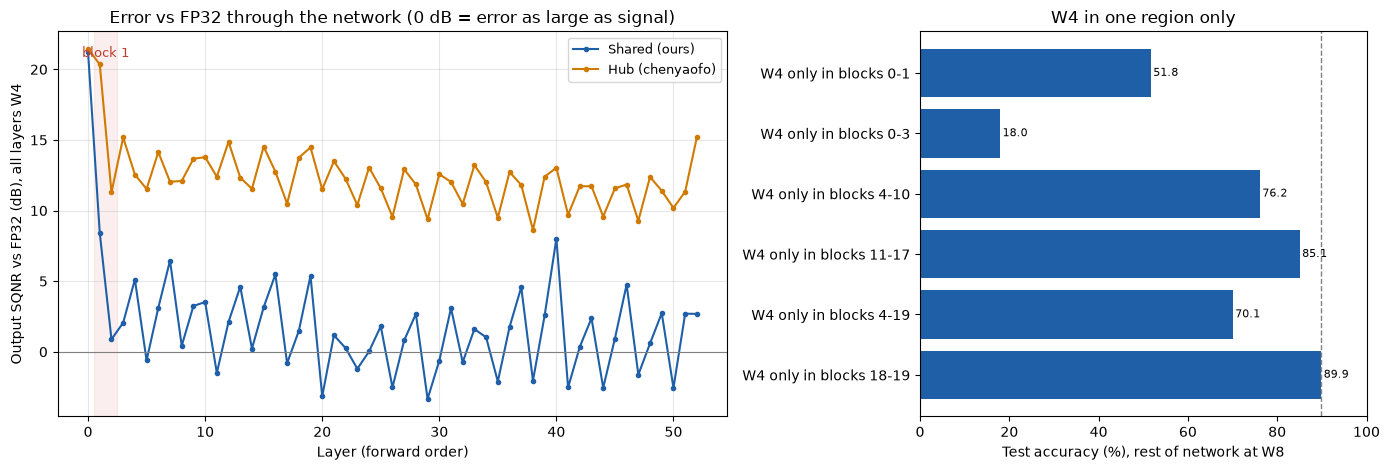

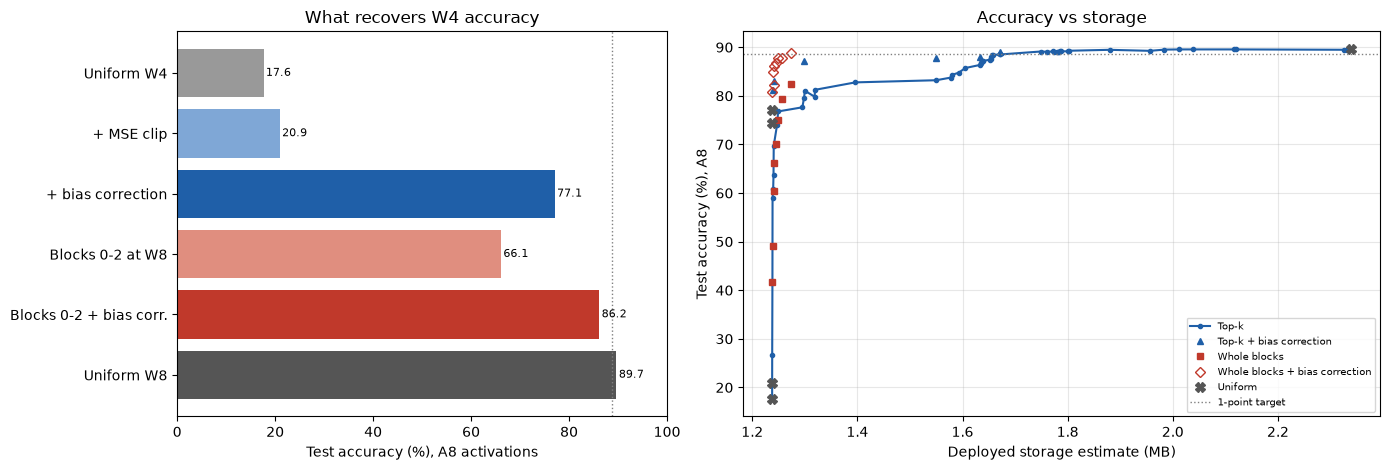

In [39]:
import json

# ---- Slide 1: where W4 breaks ----
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1.5, 1]})

ax = axes[0]
for model_name, color in colors.items():
    d = layer_quantization_error[layer_quantization_error["Model"] == model_name].sort_values("Index")
    ax.plot(d["Index"], d["Cumulative W4 output SQNR (dB)"], marker="o", ms=3, color=color, label=model_name)
ax.axvspan(0.5, 2.5, color="#c0392b", alpha=0.08)
ax.text(1.5, ax.get_ylim()[1] * 0.92, "block 1", ha="center", fontsize=9, color="#c0392b")
ax.axhline(0, color="grey", lw=0.8)
ax.set_xlabel("Layer (forward order)")
ax.set_ylabel("Output SQNR vs FP32 (dB), all layers W4")
ax.set_title("Error vs FP32 through the network (0 dB = error as large as signal)")
ax.grid(alpha=0.3)
ax.legend(fontsize=9)

ax = axes[1]
regions_plot = w4_region_results.copy()
ax.barh(regions_plot["Config"], regions_plot["Test accuracy (%)"], color="#1f5fa8")
ax.axvline(w8_reference, color="grey", ls="--", lw=1)
for i, v in enumerate(regions_plot["Test accuracy (%)"]):
    ax.text(v + 0.5, i, f"{v:.1f}", va="center", fontsize=8)
ax.set_xlabel("Test accuracy (%), rest of network at W8")
ax.set_title("W4 in one region only")
ax.invert_yaxis()
ax.set_xlim(0, 100)
fig.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "slide_1_where_it_breaks.png"), dpi=220)
plt.show()

# ---- Slide 2: what fixes it, and at what cost ----
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1, 1.3]})

ax = axes[0]
fix_labels, fix_values = [], []
for label, method, config, bc, scale in [
    ("Uniform W4", "Uniform", "W4", False, "Max scale"),
    ("+ MSE clip", "Uniform", "W4 MSE clip", False, "MSE clip"),
    ("+ bias correction", "Uniform", "W4 + bias correction", True, "Max scale"),
    ("Blocks 0-2 at W8", "Whole blocks", "Blocks 0-2", False, "Max scale"),
    ("Blocks 0-2 + bias corr.", "Whole blocks + bias correction", "Blocks 0-2", True, "Max scale"),
    ("Uniform W8", "Uniform", "W8", False, "Max scale"),
]:
    value = pick(a8_results, "A8 test accuracy (%)", Method=method, Config=config)
    fix_labels.append(label)
    fix_values.append(value)
bars = ax.barh(fix_labels, fix_values, color=["#999999", "#7fa7d6", "#1f5fa8", "#e08e7f", "#c0392b", "#555555"])
for i, v in enumerate(fix_values):
    ax.text(v + 0.5, i, f"{v:.1f}", va="center", fontsize=8)
ax.axvline(w8_a8 - 1, color="grey", ls=":", lw=1)
ax.set_xlim(0, 100)
ax.invert_yaxis()
ax.set_xlabel("Test accuracy (%), A8 activations")
ax.set_title("What recovers W4 accuracy")

ax = axes[1]
for method, style in styles.items():
    d = a8_results[a8_results["Method"] == method].sort_values("Deployed estimate (MB)")
    ax.plot(d["Deployed estimate (MB)"], d["A8 test accuracy (%)"], label=method, **style)
ax.axhline(w8_a8 - 1, color="grey", ls=":", lw=1, label="1-point target")
ax.set_xlabel("Deployed storage estimate (MB)")
ax.set_ylabel("Test accuracy (%), A8")
ax.set_title("Accuracy vs storage")
ax.grid(alpha=0.3)
ax.legend(fontsize=7, loc="lower right")
fig.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "slide_2_fixes_and_cost.png"), dpi=220)
plt.show()

## C4.2: Configs for Dana (NeuroSim)

Every Pareto-frontier config plus the whole-block configs, as per-layer weight bits with 8-bit activations.
Bias correction only changes bias values, so it does not change the hardware mapping.

In [40]:
# config_for() is defined in C3.3
handoff_configs = {}
for _, r in pd.concat([frontier, a8_results[a8_results["Method"] == "Whole blocks"]]).iterrows():
    key = f"{r['Method']} | {r['Config']}"
    if key in handoff_configs:
        continue
    handoff_configs[key] = {
        "activation_bits": ACTIVATION_BITS,
        "bias_correction": bool(r["Bias correction"]),
        "weight_scale": r["Scale"],
        "a8_test_accuracy": round(float(r["A8 test accuracy (%)"]), 2),
        "weight_payload_mb": round(float(r["Weight payload (MB)"]), 4),
        "deployed_estimate_mb": round(float(r["Deployed estimate (MB)"]), 4),
        "weight_bits": config_for(r["Method"], r["Config"], r["k"]),
    }
with open(os.path.join(OUT_DIR, "amanda_neurosim_configs.json"), "w") as f:
    json.dump(handoff_configs, f, indent=2)
print(f"Wrote {len(handoff_configs)} configs to amanda_neurosim_configs.json")

Wrote 24 configs to amanda_neurosim_configs.json


## C4.3: Handoff summary

In [41]:
def fmt(x, digits=2):
    return "n/a" if x is None or (isinstance(x, float) and math.isnan(x)) else f"{x:.{digits}f}"


shared_row = checkpoint_comparison[checkpoint_comparison["Model"] == "Shared (ours)"].iloc[0]
hub_row = checkpoint_comparison[checkpoint_comparison["Model"] == "Hub (chenyaofo)"].iloc[0]
logit_sqnr = layer_quantization_error.sort_values("Index").groupby("Model").last()["Cumulative W4 output SQNR (dB)"]
b1 = layer_quantization_error[layer_quantization_error["Layer"] == "features.1.conv.0.0"].set_index("Model")
b1w = layer_weight_stats[layer_weight_stats["Layer"] == "features.1.conv.0.0"].set_index("Model")

lines = [
    "# INT4 collapse diagnosis: handoff summary (Amanda)",
    "",
    f"Activation quantizer: {ACT_QUANT_SOURCE}, {ACTIVATION_BITS}-bit. All numbers on the full 10,000-image test set.",
    "",
    "## Checkpoint comparison (FP32 activations)",
    f"- Shared: FP32 {fmt(shared_row['FP32 (%)'])} | W8 {fmt(shared_row['W8 (%)'])} | W4 {fmt(shared_row['W4 (%)'])}",
    f"- Hub: FP32 {fmt(hub_row['FP32 (%)'])} | W8 {fmt(hub_row['W8 (%)'])} | W4 {fmt(hub_row['W4 (%)'])}",
    f"- Hub at A8: " + ", ".join(f"{k} {fmt(v)}" for k, v in hub_a8.items()),
    "",
    "## Where it breaks",
    f"- Block-1 depthwise, isolated W4 output SQNR: shared {fmt(b1.loc['Shared (ours)', 'Isolated W4 output SQNR (dB)'])} dB"
    f" vs hub {fmt(b1.loc['Hub (chenyaofo)', 'Isolated W4 output SQNR (dB)'])} dB"
    f" (W4 weight SQNR {fmt(b1w.loc['Shared (ours)', 'W4 weight SQNR (dB)'])} vs {fmt(b1w.loc['Hub (chenyaofo)', 'W4 weight SQNR (dB)'])} dB)",
    f"- Logit SQNR at uniform W4: shared {fmt(logit_sqnr['Shared (ours)'])} dB vs hub {fmt(logit_sqnr['Hub (chenyaofo)'])} dB",
    f"- Spearman(isolated W4 SQNR, midterm sensitivity drop): {fmt(spearman)}",
    f"- W4 only in blocks 0-3: {fmt(early_only)}% | W4 only in blocks 4-19: {fmt(late_only)}%",
    "",
    "## Fixes at A8",
    f"- W8/A8 {fmt(w8_a8)}% | uniform W4/A8 {fmt(pick(a8_results, 'A8 test accuracy (%)', Method='Uniform', Config='W4'))}%",
    f"- + MSE clip {fmt(pick(a8_results, 'A8 test accuracy (%)', Method='Uniform', Config='W4 MSE clip'))}%"
    f" | + bias correction {fmt(pick(a8_results, 'A8 test accuracy (%)', Method='Uniform', Config='W4 + bias correction'))}%",
]
if len(meets_target):
    r = meets_target.iloc[0]
    lines.append(f"- Chosen on validation (smallest within 1 pt of W8/A8): {r['Method']} {r['Config']} -> "
                 f"test {fmt(r['A8 test accuracy (%)'])}% (validation {fmt(r['A8 validation accuracy (%)'])}%) "
                 f"at {fmt(r['Deployed estimate (MB)'], 3)} MB deployed (W8: {fmt(w8_deployed, 3)} MB)")
else:
    lines.append("- No config reached within 1 pt of W8/A8 (negative result; see the Pareto frontier).")
lines += ["", "## Pareto frontier at A8 (deployed MB, accuracy)"]
for _, r in frontier.iterrows():
    lines.append(f"- {r['Method']} {r['Config']}: {fmt(r['Deployed estimate (MB)'], 3)} MB, "
                 f"{fmt(r['A8 test accuracy (%)'])}%")
lines += ["", "## Retrained variants"]
if len(retrain_comparison):
    for _, r in retrain_comparison.iterrows():
        lines.append(f"- {r['Variant']} ({r['Input']}, {r['Strides']} strides): FP32 {fmt(r['FP32 (%)'])} | "
                     f"W4 {fmt(r['W4 (%)'])} | W4/A8 {fmt(r.get('W4 / A8 (%)'))}")
else:
    lines.append("- Not run yet.")
lines += ["", "## Evidence table"]
for _, r in evidence.iterrows():
    lines.append(f"- **{r['Hypothesis']}** ({r['Test']}): {r['Key result']}. Suggested: {r['Suggested reading']}.")
lines += ["", "## Files (results/)"] + [f"- {f}" for f in sorted(os.listdir(OUT_DIR))]

with open(os.path.join(OUT_DIR, "amanda_handoff.md"), "w") as f:
    f.write("\n".join(lines) + "\n")
print("\n".join(lines))

# INT4 collapse diagnosis: handoff summary (Amanda)

Activation quantizer: amanda, 8-bit. All numbers on the full 10,000-image test set.

## Checkpoint comparison (FP32 activations)
- Shared: FP32 89.82 | W8 89.87 | W4 17.58
- Hub: FP32 94.05 | W8 94.02 | W4 92.84
- Hub at A8: FP32 / A8 93.95, W8 / A8 93.93, W4 / A8 92.80

## Where it breaks
- Block-1 depthwise, isolated W4 output SQNR: shared 8.79 dB vs hub 23.38 dB (W4 weight SQNR 21.39 vs 20.26 dB)
- Logit SQNR at uniform W4: shared 2.68 dB vs hub 15.19 dB
- Spearman(isolated W4 SQNR, midterm sensitivity drop): -0.70
- W4 only in blocks 0-3: 18.00% | W4 only in blocks 4-19: 70.10%

## Fixes at A8
- W8/A8 89.67% | uniform W4/A8 17.62%
- + MSE clip 20.93% | + bias correction 77.06%
- Chosen on validation (smallest within 1 pt of W8/A8): Top-k + bias correction Top-30 -> test 89.12% (validation 89.50%) at 1.671 MB deployed (W8: 2.339 MB)

## Pareto frontier at A8 (deployed MB, accuracy)
- Uniform W4 + bias correction: 1.238 MB, 77.06%
